# The Problem
####    Insurance Claims
    An Insurance Claim is a formal request by a policyholder to an insurance company for coverage or compensation for a covered loss or policy event. The insurance company validates the claim and once approved issues payment to the insured or an approved interested party on behalf of the insured.

    Our dataset also covers the insurance for vehicle, property, injury and so on..
    
    On insuring for various items by the insurer , the insurer feels there is something fishy happening and some have full faith in the organisation. So , we need to predict whether the fraud would be reported by the insurer or not.

### <font color='maroon'> Summary</font>


1. Problem Statement


2. Reading and Understanding Data

    2.1 Let us understand the attributes
    
    2.2 Understanding Data Types of the columns
    
    
3. Data Cleaning 

    3.1 Finding Null's in data 
    
    3.2 Outliers
   

4. Exploratory Data Analysis

    4.1 Univariate Analysis
        4.1.1 Categorical Features
        4.1.2 Continuous Features
    
    4.2 Multivariate analysis in Categorical Features
        
    
5. Hypothesis test using Chi-Square


6. Multivariate analysis in Continuous Features  


7. Plotting feature incident_state with various claims using Maps


8. Usage of Resampling Technique to overcome Imbalanced Data 


9. Model Building
    
    9.1 Logistic Regression
    
    9.2 Decision Tree
    
    9.3 Random Forest
    
    9.4 AdaBoost Classifier
    
    9.5 KNN
    
    
10. Hyperparameter Tuning of Above Models
    
    
11. Model Performances


### <font color='maroon'> Importing Libraries </font>

In [1]:
# Importing neccesary libraries
import pandas as pd
import numpy as np
from numpy import nan as NA
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt; plt.rcdefaults()
import seaborn as sns
import os
import plotly.offline as py
py.init_notebook_mode(connected=True)
import plotly.graph_objs as go
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook

from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, roc_auc_score
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from yellowbrick.classifier import ClassificationReport
from sklearn.feature_selection import RFE
import plotly.figure_factory as ff # visualization
from sklearn.metrics import precision_score, recall_score,f1_score


### <font color='maroon'> Reading and Understanding Data </font>

In [116]:
insurance_org = pd.read_csv('insurance_claims.csv')

In [2]:
insurance_data = pd.read_csv('insurance_claims.csv')

pd.set_option('display.max_columns',40)
insurance_data.head()

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,insured_sex,insured_education_level,insured_occupation,insured_hobbies,insured_relationship,capital-gains,capital-loss,incident_date,incident_type,collision_type,incident_severity,authorities_contacted,incident_state,incident_city,incident_location,incident_hour_of_the_day,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,17-10-2014,OH,250/500,1000,1406.91,0,466132,MALE,MD,craft-repair,sleeping,husband,53300,0,25-01-2015,Single Vehicle Collision,Side Collision,Major Damage,Police,SC,Columbus,9935 4th Drive,5,1,YES,1,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y
1,228,42,342868,27-06-2006,IN,250/500,2000,1197.22,5000000,468176,MALE,MD,machine-op-inspct,reading,other-relative,0,0,21-01-2015,Vehicle Theft,?,Minor Damage,Police,VA,Riverwood,6608 MLK Hwy,8,1,?,0,0,?,5070,780,780,3510,Mercedes,E400,2007,Y
2,134,29,687698,06-09-2000,OH,100/300,2000,1413.14,5000000,430632,FEMALE,PhD,sales,board-games,own-child,35100,0,22-02-2015,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NY,Columbus,7121 Francis Lane,7,3,NO,2,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N
3,256,41,227811,25-05-1990,IL,250/500,2000,1415.74,6000000,608117,FEMALE,PhD,armed-forces,board-games,unmarried,48900,-62400,10-01-2015,Single Vehicle Collision,Front Collision,Major Damage,Police,OH,Arlington,6956 Maple Drive,5,1,?,1,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y
4,228,44,367455,06-06-2014,IL,500/1000,1000,1583.91,6000000,610706,MALE,Associate,sales,board-games,unmarried,66000,-46000,17-02-2015,Vehicle Theft,?,Minor Damage,None,NY,Arlington,3041 3rd Ave,20,1,NO,0,1,NO,6500,1300,650,4550,Accura,RSX,2009,N


#### Data Description

    1. months_as_customer :- Months the customer is part of the insurance premium.
    2. age :- Age of the customer applied for the insurance premium
    3. policy_number:- All insurance companies file their policies by policy number rather than insured's number.
    4. policy_bind_date:- It means that the coverage date for the policy is in place.
    5. policy_state :- Depicts the state to which the policy is present
    6. policy_csl :- CSL(Combined Single Limits) states a single dollar limit that applies to any 
    combination of bodily injury and property damage liability claims, as compared to split limits where
    three seperate dollar amounts apply to each accident : per person limit, per occurence limit for all 
    injured persons.
    7. policy_deductable :- The amount the customer pays , before the insurance plan starts to pay. With a $500 deductable 
    for example, you pay the first $500 of the covered services yourself.
    8. policy_annual_premium :- The annual premium of the insurance policy . From data, we can see policies having annual premium of $1406.91
    9. umbrella_limit :- It covers a much higher limit and goes above and beyond claims directly related to auto. The
    main purpose of the umbrella policy is to protect your assets from an unforeseen event , such as tragic accident in which you are held responsible for damages or bodily injuries.
    10. insured_zip :- The zip code in which the policy was insured.
    11. insured_sex :- Gender who has insured the policy ( MALE / FEMALE )
    12. insured_education_level :- Level of Education of the insurer.
    13. insured_occupation :- Occupation of the insurer.
    14. insurer_hobbies :- Hobbies of the insurer.
    15. insurer_relationship :- The nomiee of the insurance and their relationship with the insurer.
    16. capital_gain :- If any insurance claim received on destruction of asset then profit or gain arriving from it will be Charged under income from capital gains.
    17. capital_loss :- It is essentially the difference between the purchase price and the price at which the asset is sold, where the sale price is lower than the purchase price.
    18. incident_date :- The date at which the incident took place for which insurance is claimed.
    19. collision_type :- Collision type of the asset
    20. incident_severity :- Severity of the incident which damaged the asset
    21. authorities_contacted :- Authorities contacted on the incident
    22. incident_state :- State where the incident took place
    23. incident_city :- City in which the incident took place
    24. incident_location :- Exact location where the incident occurred
    25. incident_hour_of_the_day :- At what time the incident took place in the hour of the day
    26. number_of_vehicles_involved :- Number of vehicles involved in the incident
    27. property_damage :- Whether the incident caused any property damage
    28. bodily_injuries :- Bodily injuries means physical damage to a person's body.USCS defines it as a cut, abrasion, bruise, burn, or disfigurement; physical pain ; illness; impairment of the function of a bodily member, organ, or mental faculty; or any other injury to the body, no matter how temporary.
    29. witnesses :- Evidences for claiming the insurances can be feasible through witnesses present during the incident.
    30. police_report_available :- Whether the police report is available for the incident or not??
    31. total_claim_amount :- Total amount that can be recovered through insurance claim
    32. injury_claim :-  Insuared amount that can be claimed if there is any injury caused.
    33. property_claim :- Insuared amount that can be claimed if any damage to property is caused 
    34. vehicle_claim :- Insurance amount that can be recovered for a vehicle damage
    35. auto_make :- Automobile Manufacturer of the vehicle
    36. auto_model :- Model of the automobile
    37. auto_year :- Year in which the automobile was manufactured
    38. fraud_reported :- Fraud is reported during the insurance claim or not

In [3]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 39 columns):
months_as_customer             1000 non-null int64
age                            1000 non-null int64
policy_number                  1000 non-null int64
policy_bind_date               1000 non-null object
policy_state                   1000 non-null object
policy_csl                     1000 non-null object
policy_deductable              1000 non-null int64
policy_annual_premium          1000 non-null float64
umbrella_limit                 1000 non-null int64
insured_zip                    1000 non-null int64
insured_sex                    1000 non-null object
insured_education_level        1000 non-null object
insured_occupation             1000 non-null object
insured_hobbies                1000 non-null object
insured_relationship           1000 non-null object
capital-gains                  1000 non-null int64
capital-loss                   1000 non-null int64
incident_date    

    Do you see anything off about any features?
---

    We see that column "policy_bind_date" and "incident_date" is a date  which needs to be in date format. 

In [4]:
# Col 'Policy_bind_date'  and  Col'Incident_date' converting from object to date
time_features = ['policy_bind_date','incident_date']
for features in time_features :
    insurance_data[features] = pd.to_datetime(insurance_data[features])

In [5]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 39 columns):
months_as_customer             1000 non-null int64
age                            1000 non-null int64
policy_number                  1000 non-null int64
policy_bind_date               1000 non-null datetime64[ns]
policy_state                   1000 non-null object
policy_csl                     1000 non-null object
policy_deductable              1000 non-null int64
policy_annual_premium          1000 non-null float64
umbrella_limit                 1000 non-null int64
insured_zip                    1000 non-null int64
insured_sex                    1000 non-null object
insured_education_level        1000 non-null object
insured_occupation             1000 non-null object
insured_hobbies                1000 non-null object
insured_relationship           1000 non-null object
capital-gains                  1000 non-null int64
capital-loss                   1000 non-null int64
incident_

In [6]:
# Let us see the descriptive statistics of the dataframe
insurance_data.describe()

,months_as_customer,age,policy_number,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_year
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,203.954000,38.948000,546238.648000,1136.000000,1256.406150,1.101000e+06,501214.488000,25126.100000,-26793.700000,11.644000,1.83900,0.992000,1.487000,52761.94000,7433.420000,7399.570000,37928.950000,2005.103000
std,115.113174,9.140287,257063.005276,611.864673,244.167395,2.297407e+06,71701.610941,27872.187708,28104.096686,6.951373,1.01888,0.820127,1.111335,26401.53319,4880.951853,4824.726179,18886.252893,6.015861
min,0.000000,19.000000,100804.000000,500.000000,433.330000,-1.000000e+06,430104.000000,0.000000,-111100.000000,0.000000,1.00000,0.000000,0.000000,100.00000,0.000000,0.000000,70.000000,1995.000000
25%,115.750000,32.000000,335980.250000,500.000000,1089.607500,0.000000e+00,448404.500000,0.000000,-51500.000000,6.000000,1.00000,0.000000,1.000000,41812.50000,4295.000000,4445.000000,30292.500000,2000.000000
50%,199.500000,38.000000,533135.000000,1000.000000,1257.200000,0.000000e+00,466445.500000,0.000000,-23250.000000,12.000000,1.00000,1.000000,1.000000,58055.00000,6775.000000,6750.000000,42100.000000,2005.000000
75%,276.250000,44.000000,759099.750000,2000.000000,1415.695000,0.000000e+00,603251.000000,51025.000000,0.000000,17.000000,3.00000,2.000000,2.000000,70592.50000,11305.000000,10885.000000,50822.500000,2010.000000
max,479.000000,64.000000,999435.000000,2000.000000,2047.590000,1.000000e+07,620962.000000,100500.000000,0.000000,23.000000,4.00000,2.000000,3.000000,114920.00000,21450.000000,23670.000000,79560.000000,2015.000000


### <font color = 'maroon'> Data Cleaning </font>

#### <font color='maroon'> Finding Null's in data </font>

In [7]:
insurance_data.isnull().sum()

months_as_customer             0
age                            0
policy_number                  0
policy_bind_date               0
policy_state                   0
policy_csl                     0
policy_deductable              0
policy_annual_premium          0
umbrella_limit                 0
insured_zip                    0
insured_sex                    0
insured_education_level        0
insured_occupation             0
insured_hobbies                0
insured_relationship           0
capital-gains                  0
capital-loss                   0
incident_date                  0
incident_type                  0
collision_type                 0
incident_severity              0
authorities_contacted          0
incident_state                 0
incident_city                  0
incident_location              0
incident_hour_of_the_day       0
number_of_vehicles_involved    0
property_damage                0
bodily_injuries                0
witnesses                      0
police_rep

    From the observation, we see that there aren't any null values in the dataset. Do you think there can be nulls in disguise?
---
    
    It is possible to have nulls in disguise, try checking value_counts for all variables to find potential disguised nulls

### <font color ='maroon'> Outliers </font>

    Outliers are the patterns which create noise in the dataset and these are to be identified initially and removed from the dataset. Similar, to the way a part of a vehicle does not allow the vehicle to travel smoothly. An outlier too acts in the similar fashion.
    As we all know for determining "Outliers" we make use of boxplot, which needs more information rather than mean, median and mode in terms of dispersion. 

In [8]:
# Extracting the continuous variables
cont_cols = []
for col in insurance_data.select_dtypes(include = ["float64","int64"]):
    cont_cols.append(col)
    

In [9]:
cont_cols

['months_as_customer',
 'age',
 'policy_number',
 'policy_deductable',
 'policy_annual_premium',
 'umbrella_limit',
 'insured_zip',
 'capital-gains',
 'capital-loss',
 'incident_hour_of_the_day',
 'number_of_vehicles_involved',
 'bodily_injuries',
 'witnesses',
 'total_claim_amount',
 'injury_claim',
 'property_claim',
 'vehicle_claim',
 'auto_year']

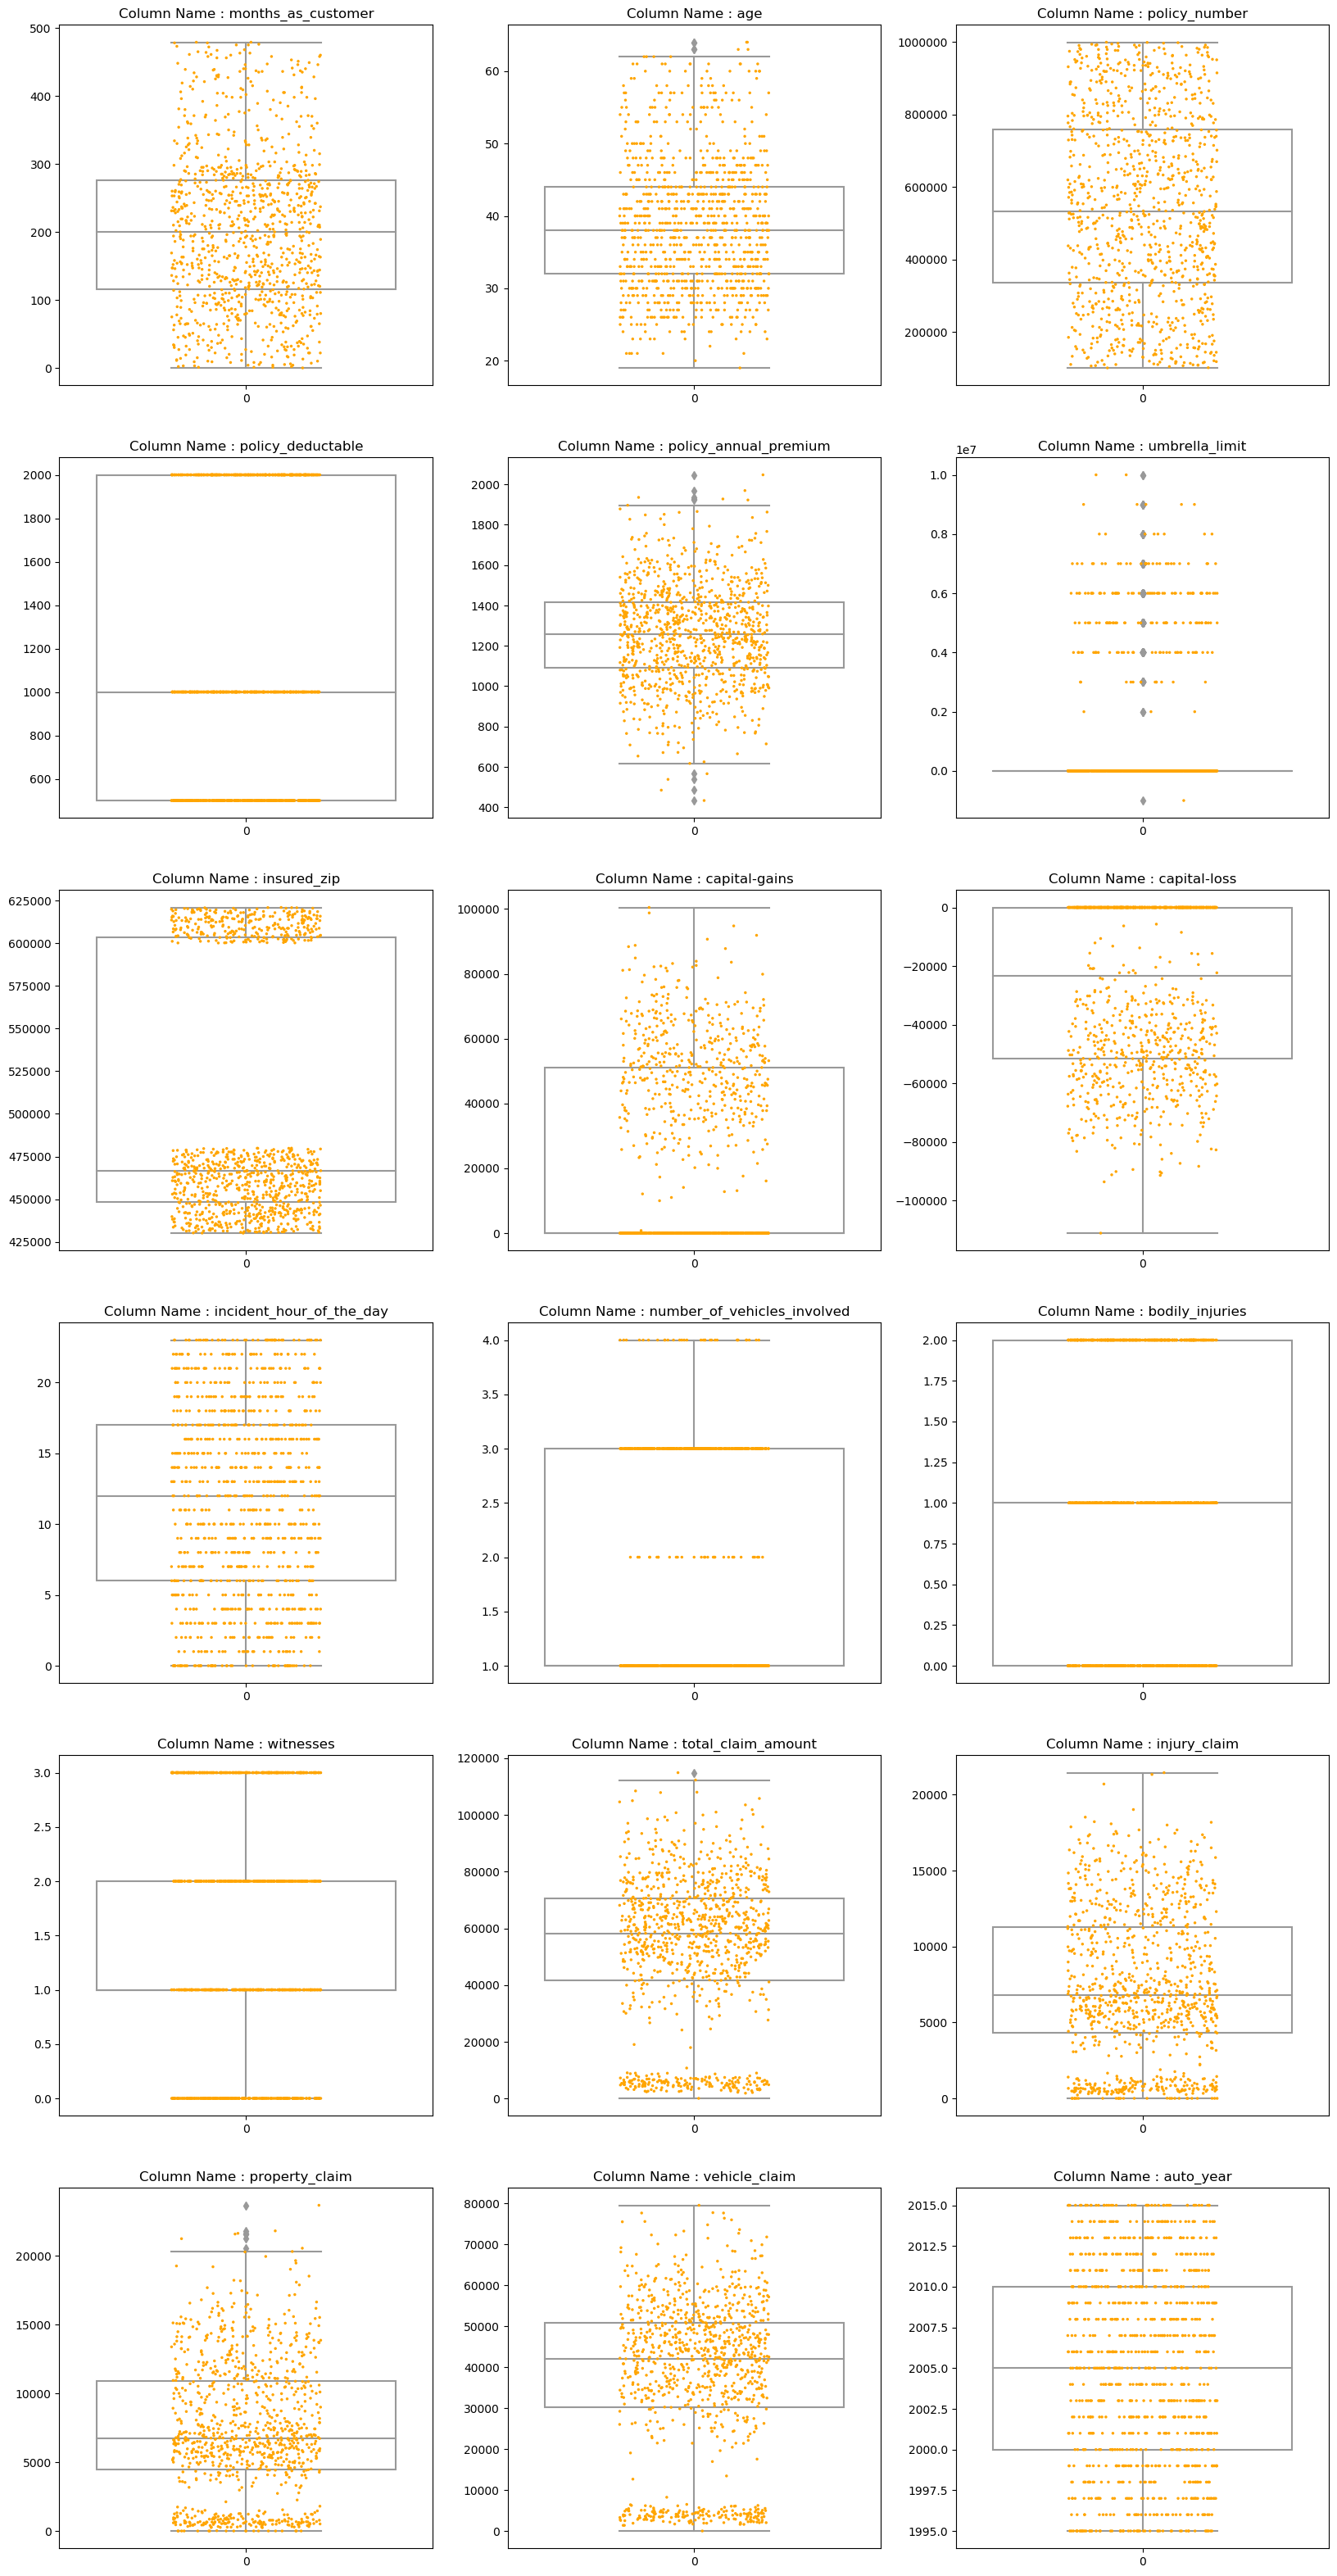

In [10]:
# Display the outliers
n = 0
nrows = 6
ncols = 3
this = []
width = 20
height = 40

for column in insurance_data[cont_cols]:
    this.append(column)
fig, axes = plt.subplots(nrows,ncols, sharex= False, sharey=False, figsize=(width,height))
for row in range(nrows):
    for cols in range(ncols):
        g = sns.boxplot(data = insurance_data[this[n]], ax=axes[row][cols],color='white')
        g = sns.stripplot(data = insurance_data[this[n]], color='orange',jitter=0.2, size=2.5, ax=axes[row][cols])
        axes[row,cols].set_title('Column Name : {}'.format(this[n]))
        
        n += 1
                                

plt.show();
             
    


#### <font color='maroon'> Inferences</font>:-

    1. Column 'age' shows there are insurers who are aged above 60 and they are considered outliers based on 
    graph. However, there can be insurers claiming 'Health insurance' who are 60 and above.

    2. Column 'policy_annual_premium' have annual premium < \\$600 and > \\$1900 shown as outliers. However, insurers can have a policy which is for
    less amount, so some insureres apply for policy for large amount.

    3. Column 'umbrella_limit' is having limits less than 0 which can be the umbrella policy is unsued and for other data points which are > 0.2 , it means when all the other policy claim got exhausted , then umbrella is being used.

    4. Column 'total_claim_amount' is depicting a claim > 100000 and < 120000 as an outlier. But their might be possibility that amount can be spent on insurance.

    5. Column 'property_claim' also shows few data points ranging above 20000 . May be there are insurers who have paid hefty insurance for proprties. 

### <font color ='maroon'>Exploratory Data Analysis</font>
    
    We will be finding out the distribution of the various features indiviually and along with target variable.

#### <font color = 'maroon'> Univariate Analysis</font>
    Let us see how the target variable 'fraud_reported' is distributed.

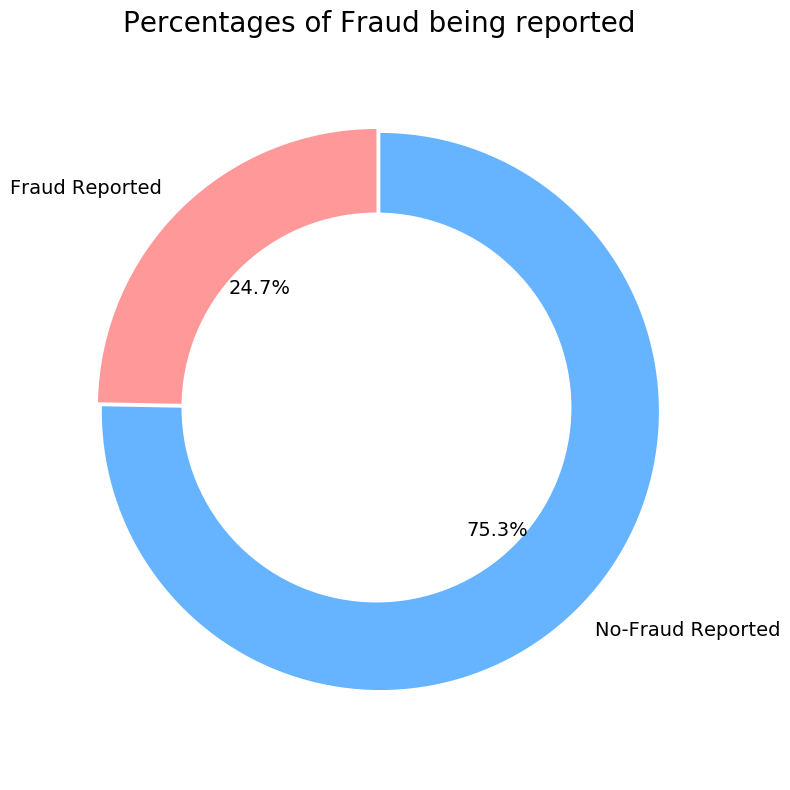

In [11]:
labels = 'Fraud Reported', 'No-Fraud Reported'
sizes = [insurance_data.fraud_reported[insurance_data['fraud_reported']== 'Y'].count(),
        insurance_data.fraud_reported[insurance_data['fraud_reported']== 'N'].count()]

colors = ['#ff9999','#66b3ff']

explode = (0,0.02)
fig, ax = plt.subplots(figsize=(8,8))
ax.pie(sizes, colors = colors, labels = labels, autopct='%1.1f%%',startangle=90, explode=explode, textprops={'fontsize':14})

# draw circle
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf() # gcf --> get current figure
fig.gca().add_artist(centre_circle)

# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')
plt.title("Percentages of Fraud being reported",size=20)
plt.tight_layout()
plt.show()

    We see lot of imbalance in dataset among "Fraud" and "No-Fraud" reporting. What should we do to get around it?
---

    It is advisable to use resampling technique, for achieving a balanced dataset. 

##### <font color ='maroon'>Categorical Features</font>
    Let us understand the distribution of Categorical Features

In [12]:
def visualize_plot(df,tgt_col,object_mode=True):
    n = 0
    this = []
    
    if object_mode:
        n_rows = 6
        n_cols = 3
        width = 20
        height = 40
    else:
        n_rows = 6
        n_cols = 3
        width = 30
        height = 40
        
    for column in df.columns:
        if object_mode:
            if (df[column].dtypes == 'O'):
                this.append(column)
        
        else:
            if (df[column].dtypes != 'O') & (df[column].dtypes != 'datetime64[ns]'):
                this.append(column)
                
    
    fig, ax = plt.subplots(n_rows, n_cols, sharex=False, sharey=False, figsize=(width,height))
    for row in range(n_rows):
        for col in range(n_cols):
            if object_mode:
                g = sns.countplot(df[this[n]], ax=ax[row][col])
        
            else:
                g = sns.distplot(df[this[n]], ax=ax[row][col])
        
              
               
            ax[row,col].set_title("Column Name: {}".format(this[n]),fontsize=20.0)
            ax[row,col].set_xlabel("",fontsize=20.0)
            ax[row,col].set_ylabel("")
            
            n += 1
    
    
    
    plt.show();
    return 

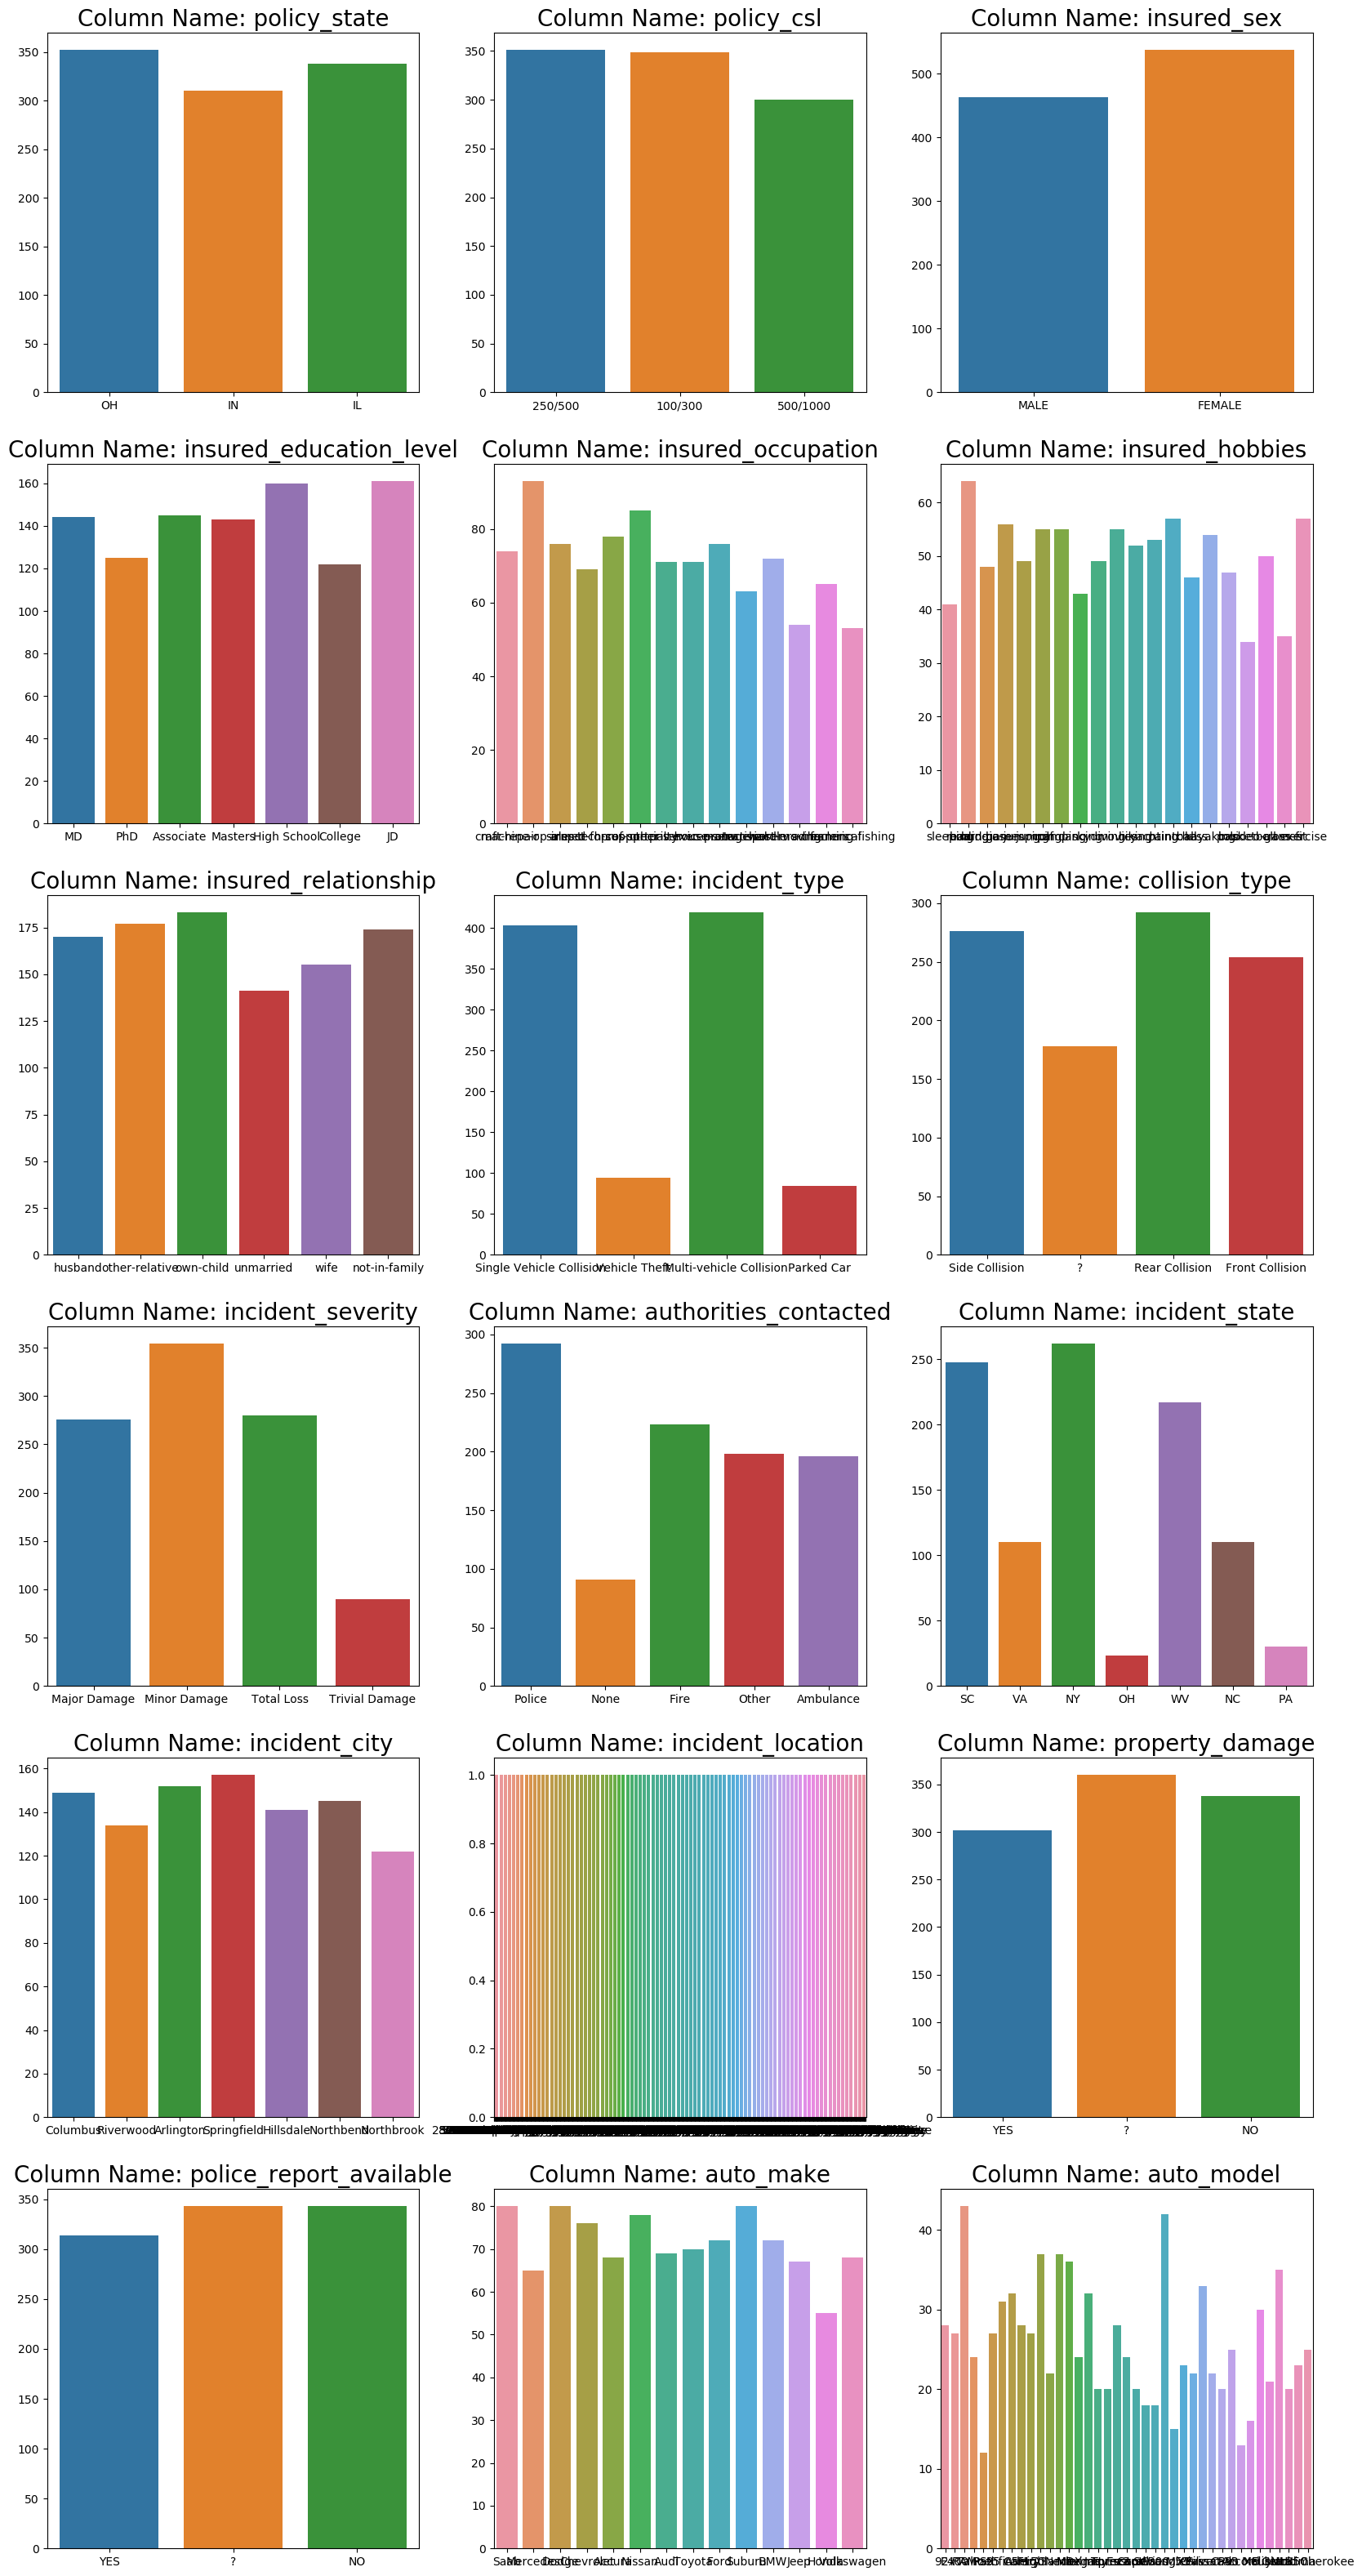

In [13]:
visualize_plot(insurance_data,'fraud_reported',object_mode=True)

#### <font color='maroon'> Obeservations from Categorical Features </font>

    1. Column 'policy_state' shows us to which state the insurance policy belongs to . From the data, 
    we see that Insurance policy belongs to OH : 'Ohio', IN : 'Indiana' and IL : 'Illionis' states.Among which 'Ohio' insurers claimed the highest insurance.

    2. Column 'policy_csl' shows that the 'combined_single_limits' belonging to bodilyinjured, property_damaged
    and vehicle damaged are of 3 types (250/500), (100/300) and (500/1000). Among which 250/500 and 100/300 have higher policy_csl insurance_claim rate.

    3. Column 'insured_sex' depicts that Female have higher insurance claim rate than Male.

    4. Column 'insured_education_level', we got different abbreviations . Let us understand those , first:-
        - MD  :- Medical Education
        - PhD :- Post-Graduate
        - Associate :- Associate Degree is similar to Bachelors' degree in India
        - Masters :- Masters Degree ( M.B.A , M.S..)
        - High School :- Insurers who have studied only upto High-School
        - College :- Insurers who have education level upto a College.
        - JD :- It means Juris Doctor, which is equivalent to our LLB degree

    Now, by knowing all the U.S Education degrees we see insurers of education level 'JD' or 'High School' the claiming the insurance most.

    5. Also, we observe that columns 'insured_occupation','insured_hobbies','incident_location','auto_make'
    and 'auto_model' have multi-labels. We use analyse it seperately.

    6. Coming to column 'insured_relationship' has labels such as 'Husband', 'other-relative','own-child',
    'unmarried','wife'and 'not-in-family'( can consist of friends, collagues or known persons).
    'own-child' label claims most insurance followed by 'other relatives' \. 'other relatives' can be parents, sisters, cousins etc.

    7. Column 'incident_type' consists of 'Single-vehicle collision','Vehicle Theft','Multi-vehicle collision' 
    and 'Parked car'. Among which  'Multi-vehicle collision' has claimed the highest insurance.

    8. In Column 'collision_type' we see the 'Side collision','Rear collision', 'Front collision' and some are 'unknown' from the data. 
    We will label the unknown collision. Rear collision is reported the most and insurance claim is provided for it.
    Rear collision can be the collision damage caused by the rear impact i.e. damage of trunk. While this may not affect 
    the ability to drive the vehicle , it can present a safety issue and will undoubtedly reduce the value
    of the car. 

    9. Column 'incidence_severity' has severities ranging from Minor, Major, Total Loss and Trivial Damage. 
    And maximum insurance is claimed for Minor incidents.

    10. Column 'authorities_contacted' shows the authorities such as Police, Ambulance, Fire, Other or no authorities
    contacted during the incidence.

    11. Similar to column 'policy_state' we will list down the 'incident_state' 
        - 'SC' : 'South Carolina'
        - 'VA' : 'Virginia'
        - 'NY' : 'New York'
        - 'OH' : 'Ohio'
        - 'WV' : 'West Virgnia'
        - 'NC' : 'North Carolina'
        - 'PA' : 'Pennsylvania'

    12.Column 'Property_damage' has 3 labels such as 'YES' ,'NO' and rest are unknown. Since, we are not
    aware of the details whether the property got damaged or not for few labels, we can mark them as 'NO'.

    13. Column 'police_report_available' shows it is available for few, some known and the rest unknown. 
    For unknown, it is better to consider as 'NO'.




##### <font color ='maroon'>Column insured_occupation</font>

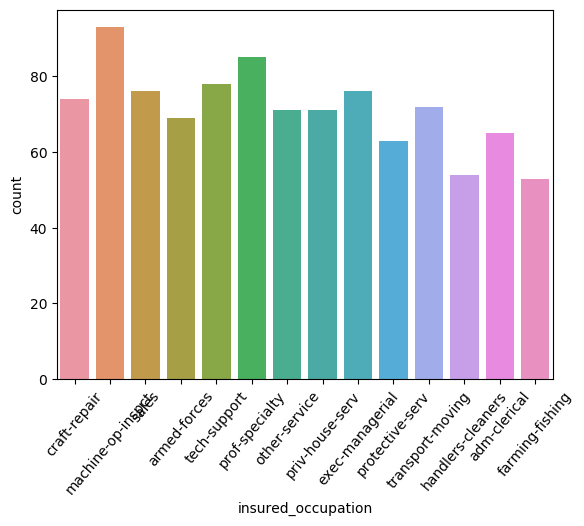

In [14]:
sns.countplot(insurance_data['insured_occupation'])
plt.xticks(rotation=50)
plt.show()

    From graph, we can observe that machine operators and prof-speciality are the ones claiming the max. insurances.
    It might be due to machine-operator using maximum automotives for which insurance claim is needed. On the other hand, Professional Speciality is a medical practitioner and health insurances are claimed by them for the bodily injured.

##### <font color='maroon'> Column insured_hobbies</font>

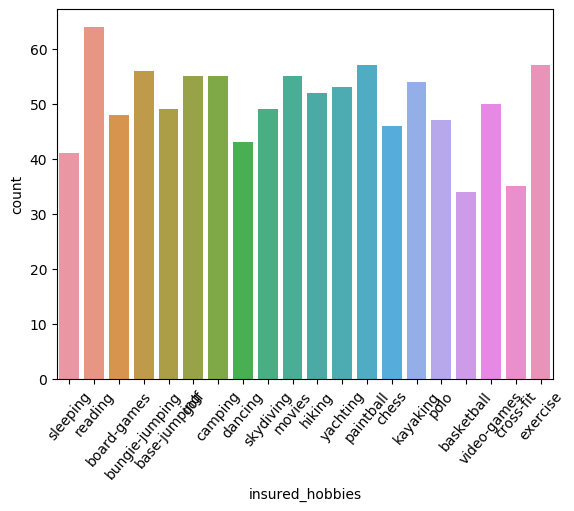

In [15]:
sns.countplot(insurance_data['insured_hobbies'])
plt.xticks(rotation=50)
plt.show()

    We infer that the insurers are fond of reading stuff, the insurers who claim the insurances
    might be aware of the policies while availing the insurance . Also , they do exercise a lot and like to 
    be fit in the long run. 

##### <font color ='maroon'>Column incident_city</font>

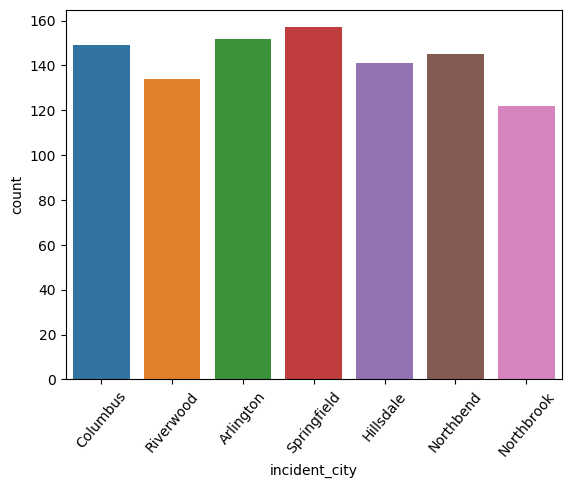

In [16]:
sns.countplot(insurance_data['incident_city'])
plt.xticks(rotation=50)
plt.show()

    We see that cities that have reported incidents under Insurance claim are 'Springfield' followed by 'Arlington' and 'Columbus'.

##### <font color='maroon'> Column incident_location</font>

    Each incident is reported in an unique location, likewise if is difficult to plot locations for 1000 labels. Hence, we are listing out the first 10 rows incident locations.

In [17]:
insurance_data['incident_location'].value_counts()[0:10]

6191 Oak Lane         1
3282 4th Lane         1
5862 Apache Ridge     1
4234 Cherokee Lane    1
8576 Andromedia St    1
3227 Maple Ave        1
1512 Rock Lane        1
8621 Best Ridge       1
9138 3rd St           1
6259 Lincoln Hwy      1
Name: incident_location, dtype: int64

##### <font color='maroon'> Column auto_make</font>

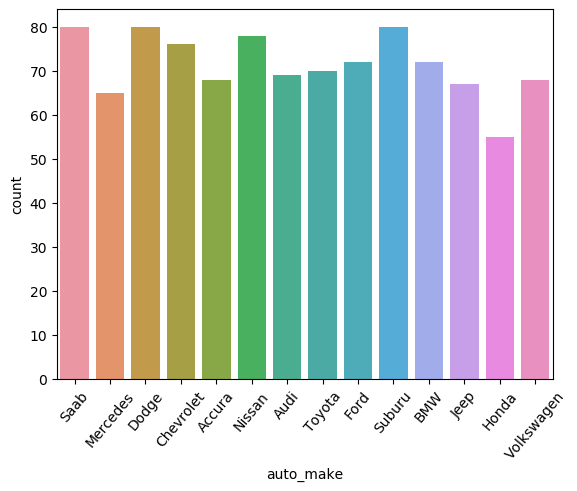

In [18]:
sns.countplot(insurance_data['auto_make'])
plt.xticks(rotation=50)
plt.show()

    Among the various automobiles listed , the top 5 automobiles which are majorly listed in the insurance claim are 'Suburu', 'Saab','Dodge', 'Nissan' and 'Chevrolet'.

##### <font color='maroon'>Column auto_model</font>

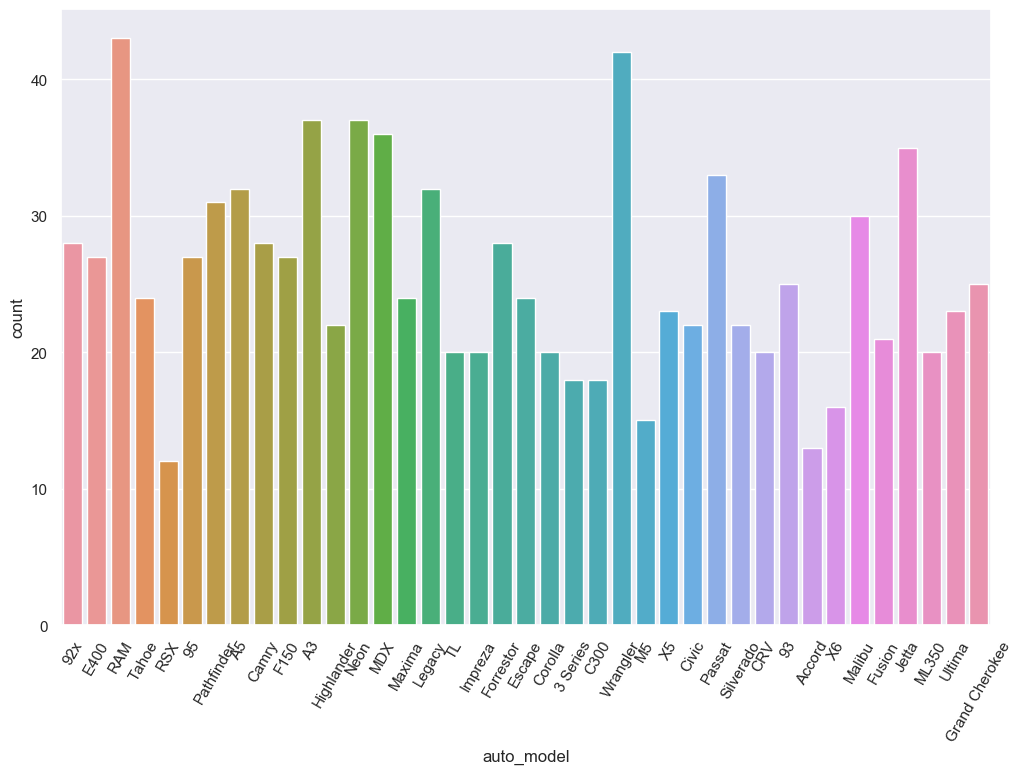

In [19]:
sns.set(rc={'figure.figsize':(12,8)})
sns.countplot(insurance_data['auto_model'])
plt.xticks(rotation=60)

plt.show()

    We infer that 'Wrangler' model which belongs to 'Jeep' has reported lots of incidents and claiming insurance, followed by 'RAM' model of 'Dodge' which is a small truck and 'A3' model a car which belongs to 'Audi'.

##### <font color='maroon'> Column collision_type</font>

In [20]:
insurance_data['collision_type'] = insurance_data['collision_type'].map({'Side Collision' : 'Side Collision',
                                                                         'Front Collision' : 'Front Collision',
                                                                         'Rear Collision' : 'Rear Collision',
                                                                         '?':'Unknown'})

In [21]:
insurance_data['collision_type'].value_counts()

Rear Collision     292
Side Collision     276
Front Collision    254
Unknown            178
Name: collision_type, dtype: int64

##### <font color='maroon'> Column property_damage </font>

In [22]:
insurance_data['property_damage'] = insurance_data['property_damage'].map({'YES' : 'YES',
                                                                            '?' : 'NO',
                                                                            'NO' : 'NO'})

In [23]:
insurance_data['property_damage'].value_counts()

NO     698
YES    302
Name: property_damage, dtype: int64

##### <font color='maroon'> Column police_report_available</font>

In [24]:
insurance_data['police_report_available'] = insurance_data['police_report_available'].map({'YES' : 'YES',
                                                                                           '?' : 'NO',
                                                                                           'NO' : 'NO'})

In [25]:
insurance_data['police_report_available'].value_counts()

NO     686
YES    314
Name: police_report_available, dtype: int64

#### <font color='maroon'> Continuous features</font>

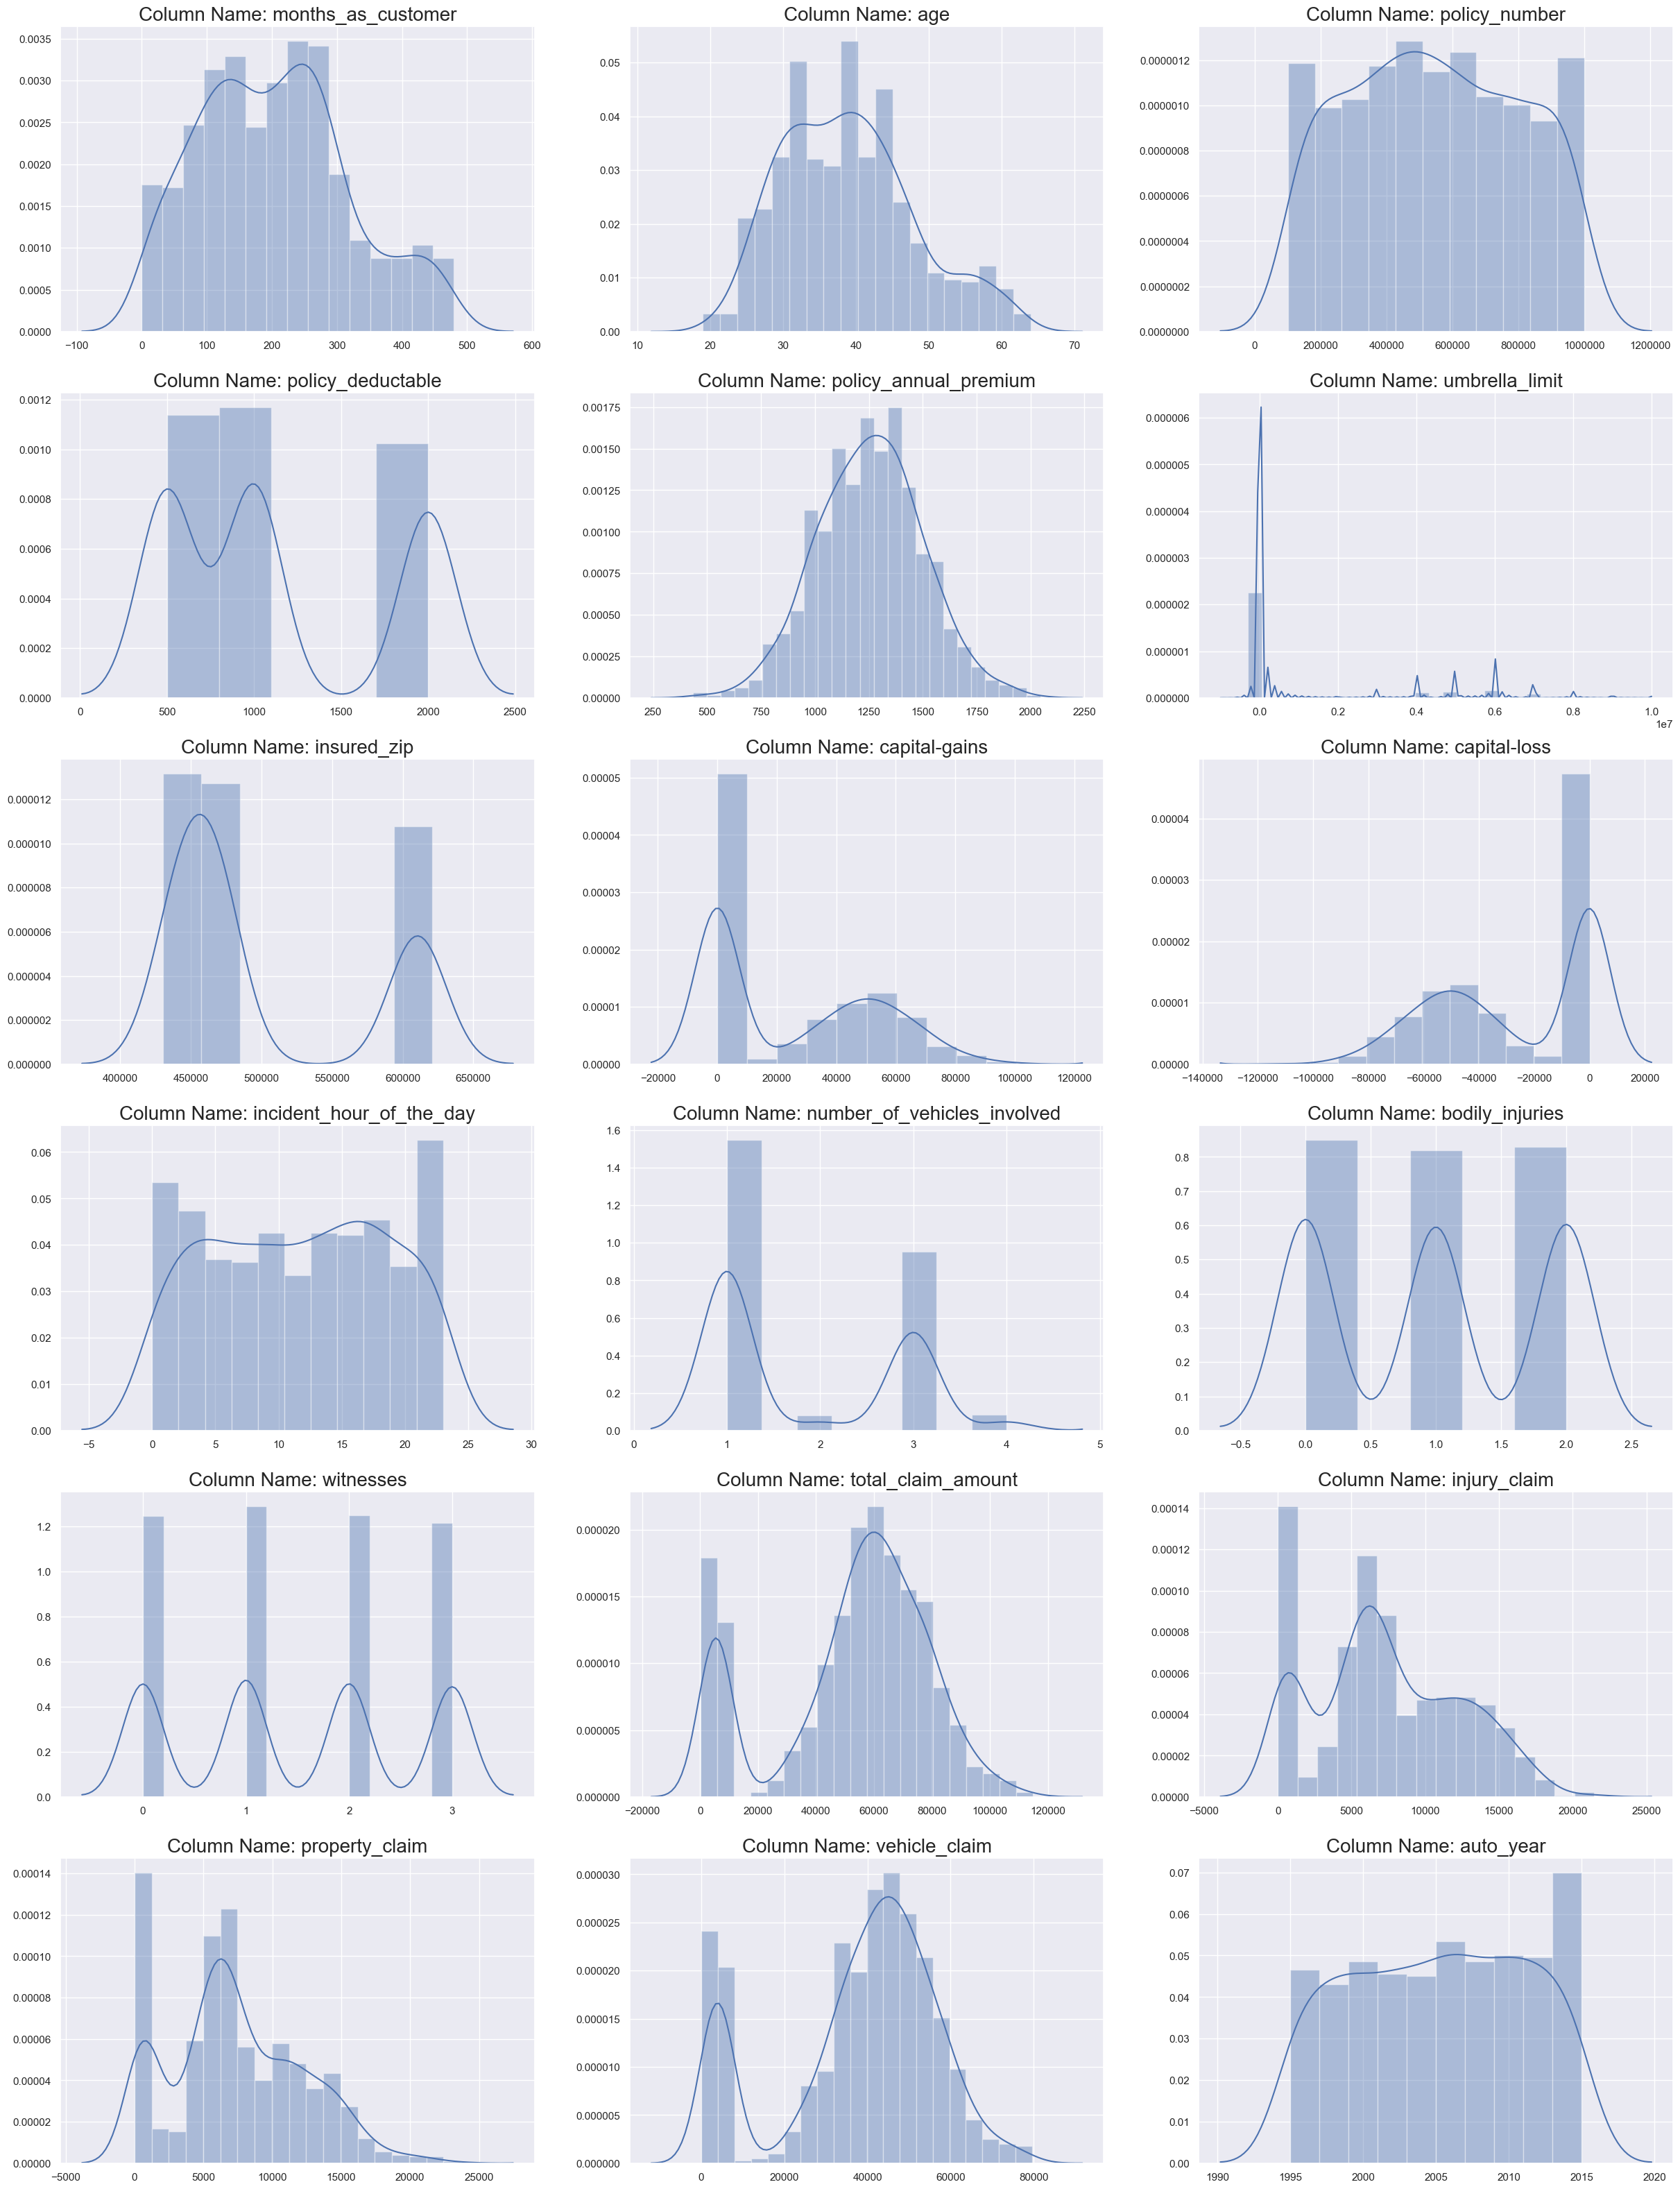

In [26]:
visualize_plot(insurance_data,'fraud_reported',object_mode=False)

##### <font color='maroon'> Inferences from Continuous Variables</font>
    1. Features such as "months_as_customer","age","policy_number","policy_annual_premium",
    "total_claim_amount","injury_claim","property_claim" and "vehicle_claim"  are normally distributed.

    2. Converting continuous features such as "policy_deductable","number_of_vehicles_involved", "bodily_injuries" and "witnesses" to categorical features as they look nominal in nature.

    3. Customers are insuring their insurances from 0 months to max. 500 months.

    4. Age group which is claiming insurance is ranging from 20 years to 60 years.

    5. Policy number within 200000 to 1000000 are claiming the insurance.

    6. Annual policy premium which the insurers pay ranges anywhere between \\$750 to \\$1750.

    7. Looks like most of the insurers don't use the umbrella limit.

    8. Insurers are the using the zip code in the number series 450000XXX and so on..

    9. On the other hand, capital-gains and capital-losses are mostly null. While few insurers have
    capital gains ranging between \\$20000 to \\$80000 where there are insurers who are observing capital losses
    drasatically upto \\$100000.

    10. Insurers have total claim amount ranging from \\$20000 to \\$110000.

    11. Injury and Property Claims from insurers are claimed from \\$5000 to \\$20000. While vehicle insurance
    from insurers is claimed from \\$20000 to \\$80000.


    What can we do to the features to make analysis easier?
---

    We see that few of continuous features which are nominal in nature can be converted to categorical

#### <font color='maroon'> Converting continuous features to categorical which are nominal in nature</font>

In [32]:
cont_to_cat = ['policy_deductable','number_of_vehicles_involved','bodily_injuries','witnesses']
insurance_data[cont_to_cat] = insurance_data[cont_to_cat].astype('category')

In [33]:
if len(insurance_data.select_dtypes("object"))!=0:
    cat_cols = []
    for col in insurance_data.select_dtypes("object"):
        cat_cols.append(col)
    insurance_data[cat_cols] = insurance_data[cat_cols].astype("category")

In [37]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 39 columns):
months_as_customer             1000 non-null int64
age                            1000 non-null int64
policy_number                  1000 non-null int64
policy_bind_date               1000 non-null datetime64[ns]
policy_state                   1000 non-null category
policy_csl                     1000 non-null category
policy_deductable              1000 non-null category
policy_annual_premium          1000 non-null float64
umbrella_limit                 1000 non-null int64
insured_zip                    1000 non-null int64
insured_sex                    1000 non-null category
insured_education_level        1000 non-null category
insured_occupation             1000 non-null category
insured_hobbies                1000 non-null category
insured_relationship           1000 non-null category
capital-gains                  1000 non-null int64
capital-loss                   1000 non-nul

In [41]:
cat_cols = insurance_data.select_dtypes(include='category').columns

Let us now plot the categorical features , after alteration.

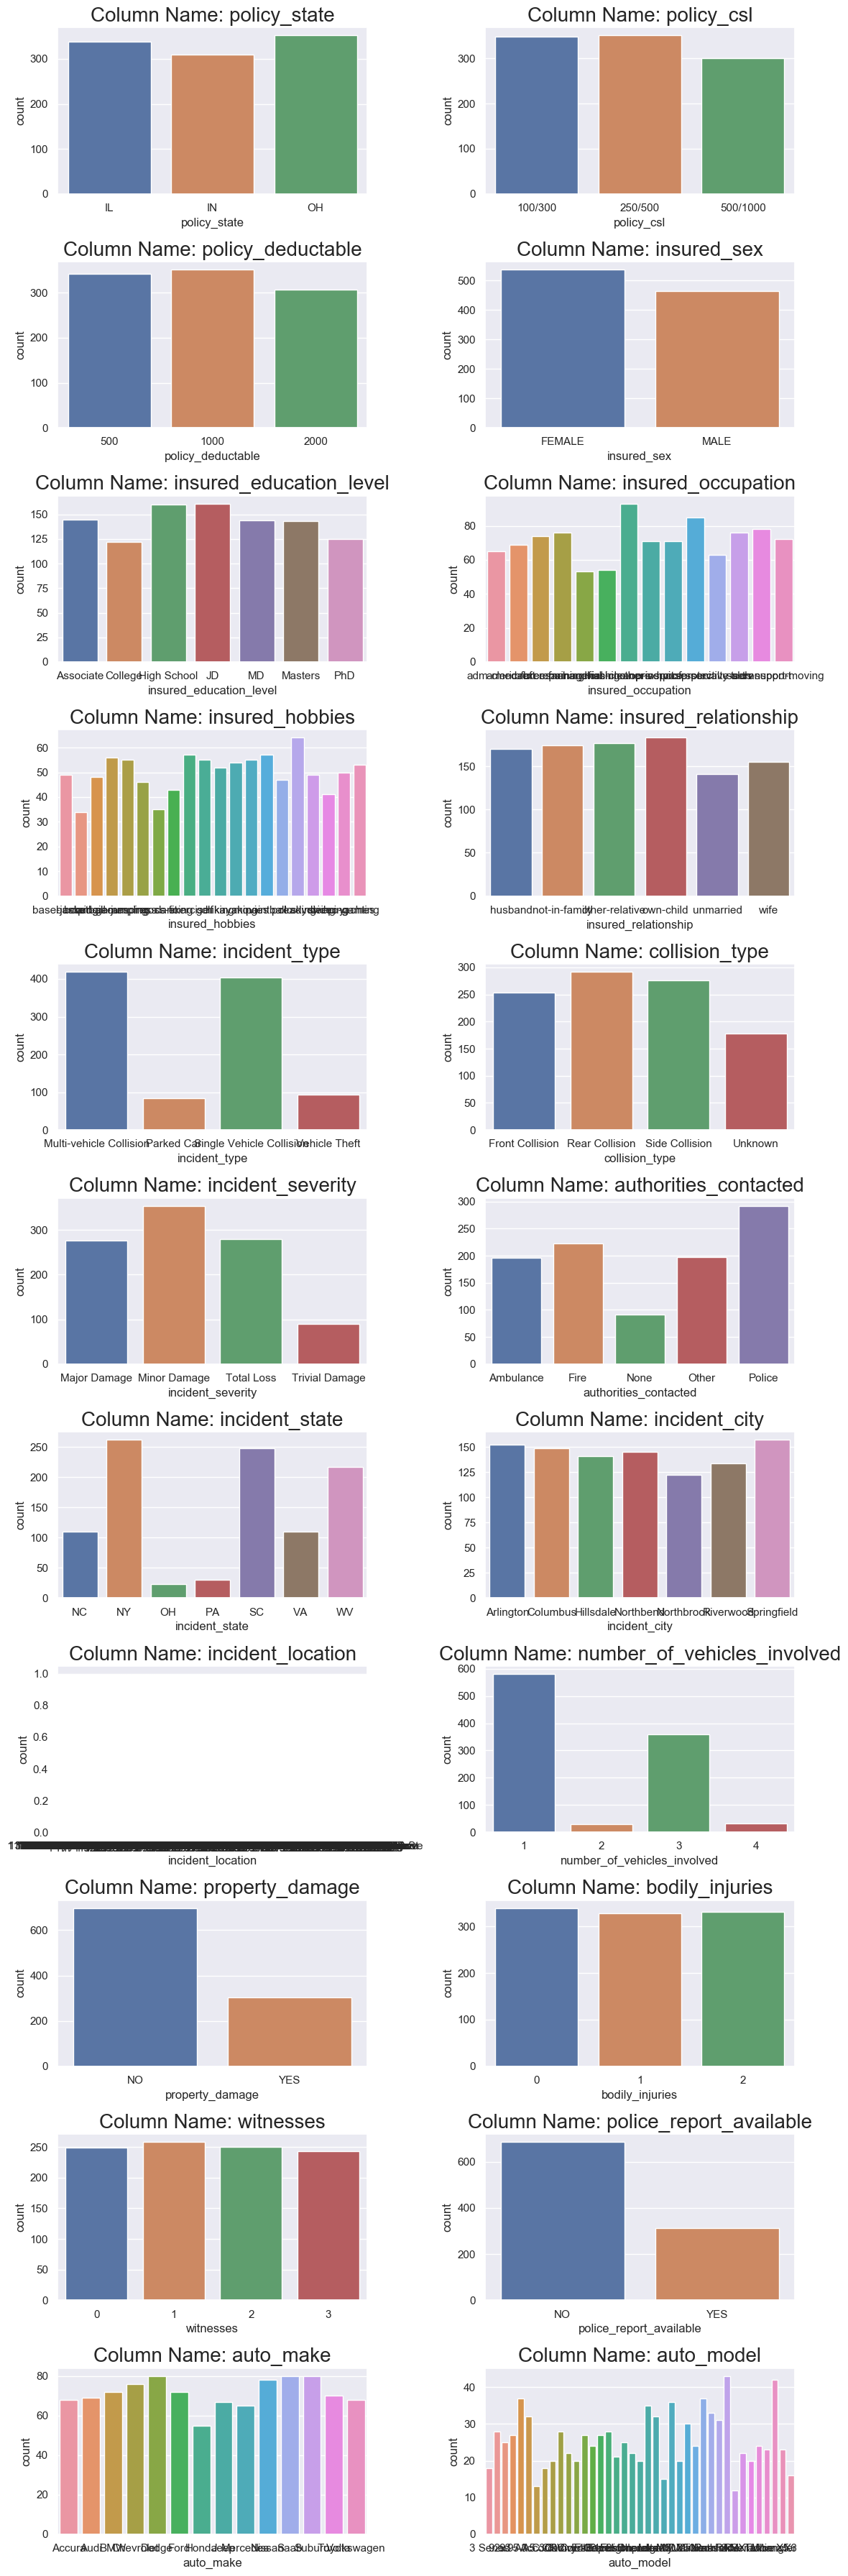

In [44]:
n=0
cat_lst = []
for cols in insurance_data[cat_cols]:
    if cols == 'fraud_reported':
        continue
    else:
        cat_lst.append(cols)
fig,ax = plt.subplots(11,2,squeeze=False,figsize=(12,36))
for row in range(11):
    for col in range(2):
        g = sns.countplot(insurance_data[cat_lst[n]],ax=ax[row][col])
            
        ax[row,col].set_title("Column Name: {}".format(cat_lst[n]),fontsize=20.0)
        n += 1
        
plt.tight_layout()
plt.show();

#### <font color='maroon'> Inferences after required changes in Categorical variables</font>

    1. In Column 'policy_deductable', \\$500 and \\$1000 is the max amount being paid by the policy holder
    before the insurance provider pays the expenses.

    2. In column 'collision_type' and 'authorities_contacted' we see new labels being added such as 'Unknown' and 'None', which
    gives us more clarity on the features.

    3. Mostly single-vehicles which are involved in collision are claiming the insurance.

    4. Also, during the incident injuries which aren't caused to the person much are incuring insurance claim.

    5. Witnesses who have witnessed such incidents are mostly single-person.


    Now that we understood each feature indiviually, let us find out the relationship of features with the target.

### <font color='maroon'>Multivariate Analysis</font>

#### <font color='maroon'> Categorical Features w.r.t Target </font>

In [45]:
def bivariate_eda(data, col1, col2,rot):
    if col2 == 'fraud_reported':
        cross_tab = pd.crosstab(data[col1], data[col2]).apply(lambda x: x/x.sum() * 100, axis = 1).round(2)
        cross_tab.sort_values('Y',ascending=False)[['Y']].plot.bar(figsize=(6,4))
        plt.xlabel('{}'.format(col1))
        plt.ylabel('% of fraud_reported')
        plt.title('{} Vs fraud_reported'.format(col1))
        plt.xticks(rotation=rot)
        plt.legend("")
        plt.figure(figsize=(6,4))
        plt.show()
        return cross_tab
        
    

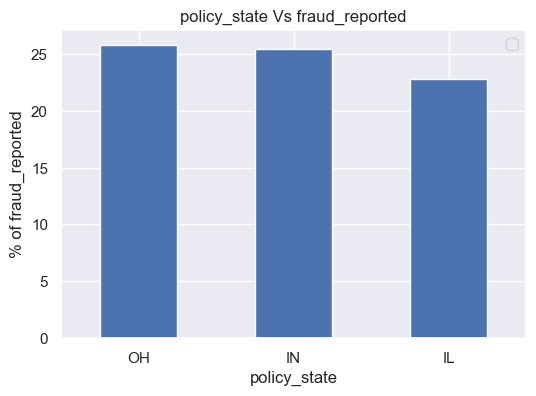

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
policy_state,,
IL,77.22,22.78
IN,74.52,25.48
OH,74.15,25.85


In [46]:
bivariate_eda(insurance_data,'policy_state','fraud_reported',0)

#### <font color='maroon'>Policy_state Vs Fraud_reported</font>

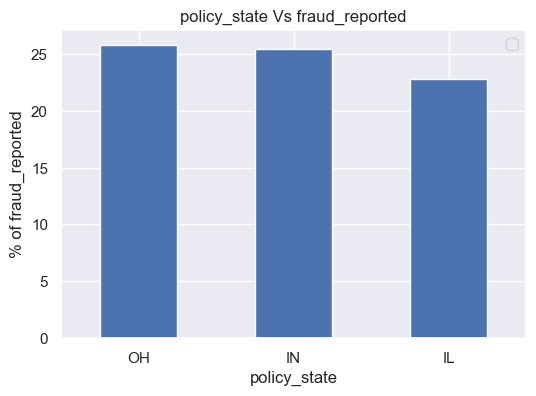

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
policy_state,,
IL,77.22,22.78
IN,74.52,25.48
OH,74.15,25.85


In [47]:
bivariate_eda(insurance_data,'policy_state','fraud_reported',0)


    States 'Indiana' and 'Ohio' have maximum amount of fraud_reported while claiming the insurance as compared to 'Illionis'. Going through the data we will try to find out various insights which are helping us in reporting fraud.

#### <font color='maroon'>policy_csl Vs Fraud_reported</font>

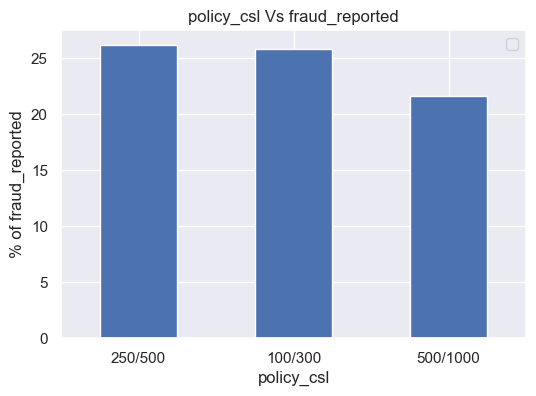

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
policy_csl,,
100/300,74.21,25.79
250/500,73.79,26.21
500/1000,78.33,21.67


In [48]:
bivariate_eda(insurance_data,'policy_csl','fraud_reported',0)

    To understand this feature better, let us consider an example where the liability coverage for a vehicle policy if written as combined single limit(CSL) , there is no differentiation between bodily injuries payout per person, per accident or property damage claims. If the liability limit is a split say \\$250/\\$500, an incident occured where the bodily injury losses and medical bills come upto say \\$400. 
    So, the insurance for only \\$400 would leave \\$150 uninsured. So, in this process the policy holders might find to tough to pay huge taxes and under hard circumstances tend to commit fraud.

#### <font color='maroon'> policy_deductable Vs fraud_reported</font>

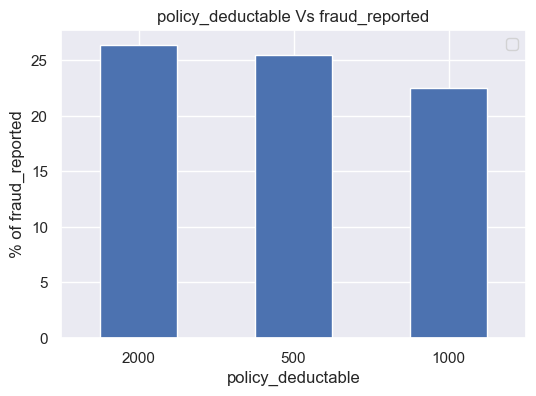

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
policy_deductable,,
500,74.56,25.44
1000,77.49,22.51
2000,73.62,26.38


In [49]:
bivariate_eda(insurance_data, 'policy_deductable','fraud_reported',0)

    From above we see that for \\$2000 as the deductable amount the policy_holders are committing lot of fraud. These are actually the expenses which are paid by the policy holders before an insurance provider will pay any expenses. Since, it is a huge amount which the policy holders could incur from the insurance providers they tend to commit frauds in claiming it.

#### <font color='maroon'>insured_sex Vs fraud_reported </font>

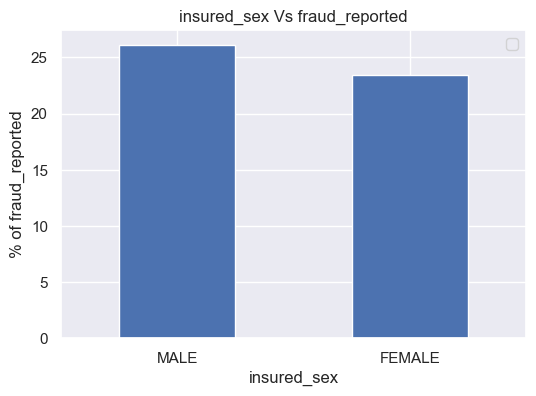

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
insured_sex,,
FEMALE,76.54,23.46
MALE,73.87,26.13


In [50]:
bivariate_eda(insurance_data,'insured_sex','fraud_reported',0)

    Males are the ones who are reported doing more frauds as compared to the females while claiming insurance.

#### <font color = 'maroon'> insured_education_level Vs fraud_reported </font>

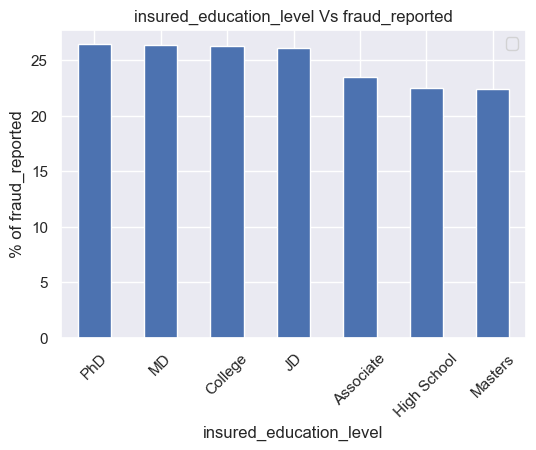

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
insured_education_level,,
Associate,76.55,23.45
College,73.77,26.23
High School,77.50,22.50
JD,73.91,26.09
MD,73.61,26.39
Masters,77.62,22.38
PhD,73.60,26.40


In [51]:
bivariate_eda(insurance_data,'insured_education_level','fraud_reported',45)

    Looking at the graph, insurers having college education can be understood of committing fraud as they may get less wages or less savings might be their with them. JD and MD educators doing frauds maybe in availing health insurance schemes.
    PhD level educators doing fraud looks astonishing . We aren't able to get any pattern out from this.

#### <font color='maroon'>insured_occupation Vs fraud_reported</font>

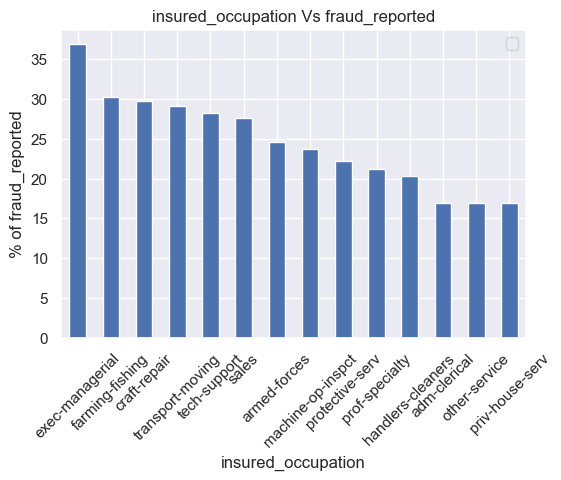

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
insured_occupation,,
adm-clerical,83.08,16.92
armed-forces,75.36,24.64
craft-repair,70.27,29.73
exec-managerial,63.16,36.84
farming-fishing,69.81,30.19
handlers-cleaners,79.63,20.37
machine-op-inspct,76.34,23.66
other-service,83.10,16.90
priv-house-serv,83.10,16.90


In [52]:
bivariate_eda(insurance_data, 'insured_occupation','fraud_reported',45)

    Insurers who work in the executive-managerial positions may have reported fraud in the health insurances, since uninsured amount would have huge taxes.
    While those who work in the 'farming-fishing' sector and 'transport-moving' sector may have done frauds in vehicle claim because of usage of heavy machinery, which would incur huge liability.

#### <font color = 'maroon'>insured_relationship Vs fraud_reported</font>

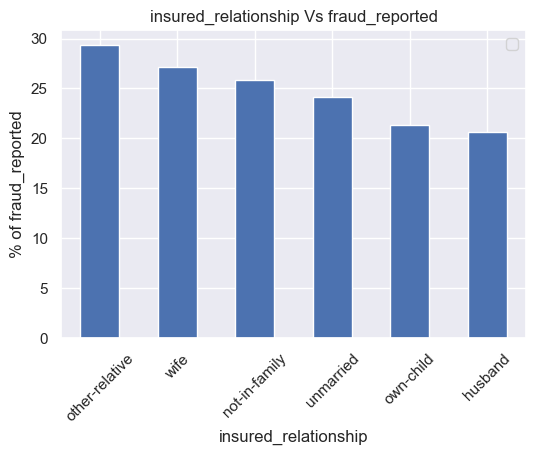

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
insured_relationship,,
husband,79.41,20.59
not-in-family,74.14,25.86
other-relative,70.62,29.38
own-child,78.69,21.31
unmarried,75.89,24.11
wife,72.90,27.10


In [53]:
bivariate_eda(insurance_data,'insured_relationship','fraud_reported',45)

    From the observation, we see that "other-relative" such as cousins, parents are the ones reporting more fraud in  comparison to wife, friends, collagues . We are not able to draw much insights from this relationship.

#### <font color='maroon'>incident_type Vs fraud_reported</font>

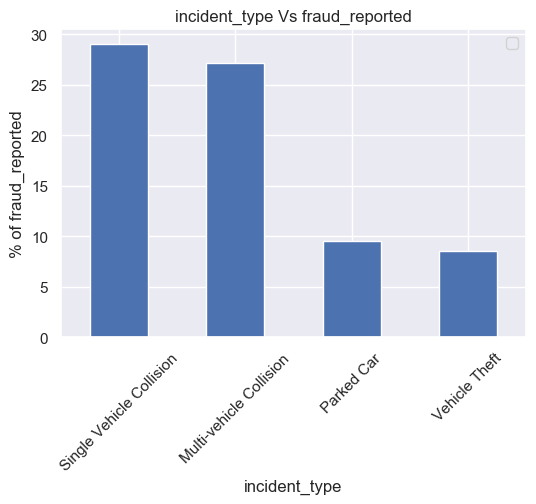

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
incident_type,,
Multi-vehicle Collision,72.79,27.21
Parked Car,90.48,9.52
Single Vehicle Collision,70.97,29.03
Vehicle Theft,91.49,8.51


In [54]:
bivariate_eda(insurance_data,'incident_type','fraud_reported',45)

    Insurers for whom "Single Vehicle Collision" and "Multi-vehicle Collision" took place have reported frauds.
    We can summarize that though the damages to the automobile may be minor or the cost of wear and tear may be not more, the chances are there that the uninsured amount would have tax deductions, so by manipulating the insurance claim the tax payment can be reduced. Hence, frauds are being reported .

#### <font color='maroon'> collision_type Vs fraud_reported </font>

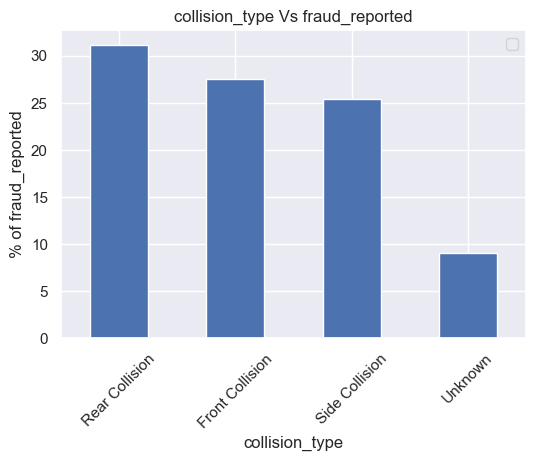

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
collision_type,,
Front Collision,72.44,27.56
Rear Collision,68.84,31.16
Side Collision,74.64,25.36
Unknown,91.01,8.99


In [55]:
bivariate_eda(insurance_data,'collision_type','fraud_reported',45)

    Rear Collision occurs when the vehicle crashes into the one in front of it. It may cause injuries to people and some damages to vehicle, which must have been exaggerated and claimed.This has led to reporting a fraud .

#### <font color='maroon'>incident_city Vs fraud_reported</font>

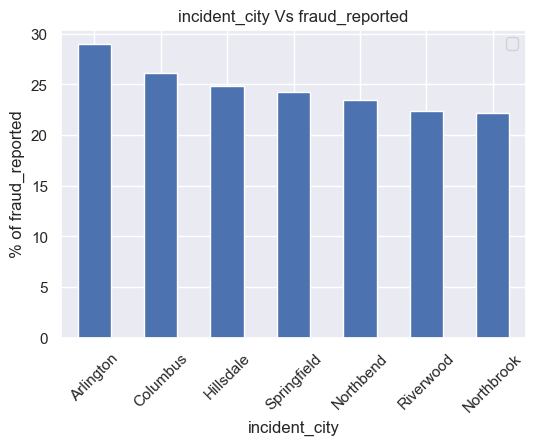

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
incident_city,,
Arlington,71.05,28.95
Columbus,73.83,26.17
Hillsdale,75.18,24.82
Northbend,76.55,23.45
Northbrook,77.87,22.13
Riverwood,77.61,22.39
Springfield,75.80,24.20


In [56]:
bivariate_eda(insurance_data,'incident_city','fraud_reported',45)

    Arlington might have health insurance providers providing insurance and their might be chances in this that the insurers can fake themselves are medical practitoners with fake license and demand more insurance coverage from insurers causing fraud in the business.

#### <font color='maroon'>witnesses Vs fraud_reported</font>

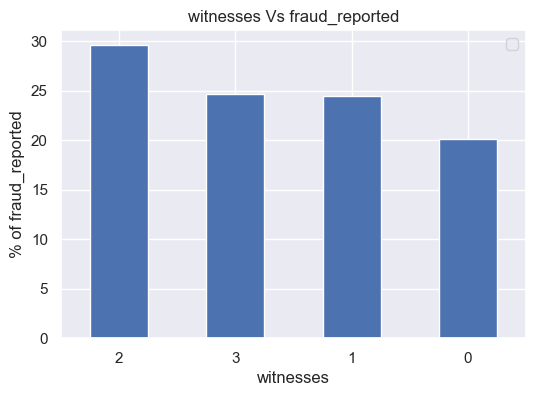

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
witnesses,,
0,79.92,20.08
1,75.58,24.42
2,70.40,29.60
3,75.31,24.69


In [57]:
bivariate_eda(insurance_data,'witnesses','fraud_reported',0)

    A min. of 2 witnesses for such incidents are the ones reporting the most fraud. May be the witnesses might have been bribed or a threat warning might have been given to them as they have seen the incident , so chances are there of committing fraud.

#### <font color='maroon'> bodily_injuries Vs fraud_reported</font>

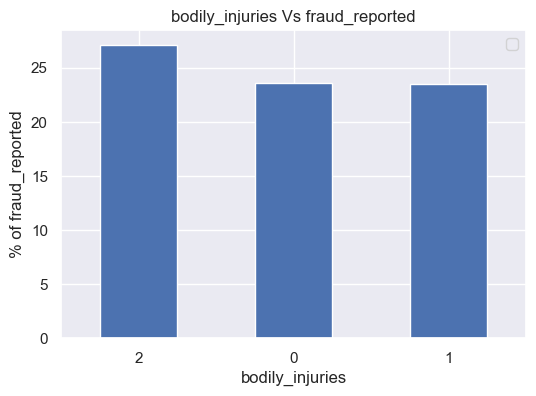

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
bodily_injuries,,
0,76.47,23.53
1,76.52,23.48
2,72.89,27.11


In [58]:
bivariate_eda(insurance_data,'bodily_injuries','fraud_reported',0)

    It is easy to infer the the injuries caused to people are more. There might be a setback in the insurance libaility too, which may led to commit fraud.

#### <font color='maroon'> auto_make Vs fraud_reported</font>

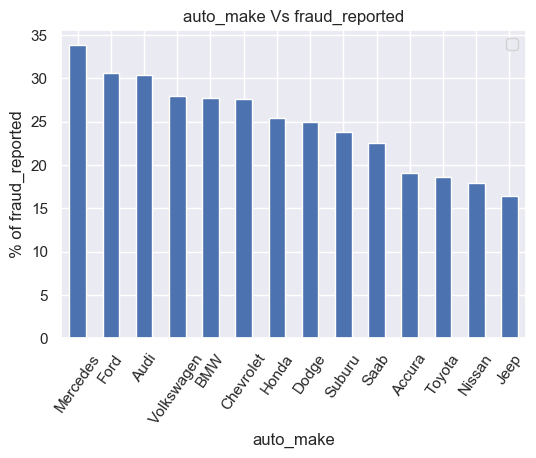

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
auto_make,,
Accura,80.88,19.12
Audi,69.57,30.43
BMW,72.22,27.78
Chevrolet,72.37,27.63
Dodge,75.00,25.00
Ford,69.44,30.56
Honda,74.55,25.45
Jeep,83.58,16.42
Mercedes,66.15,33.85


In [59]:
bivariate_eda(insurance_data,'auto_make','fraud_reported',55)

    From above , we observe that 'Mercedes' and 'Ford' automobiles are reporting more frauds.

#### <font color='maroon'> police_report_available Vs fraud_reported </font>

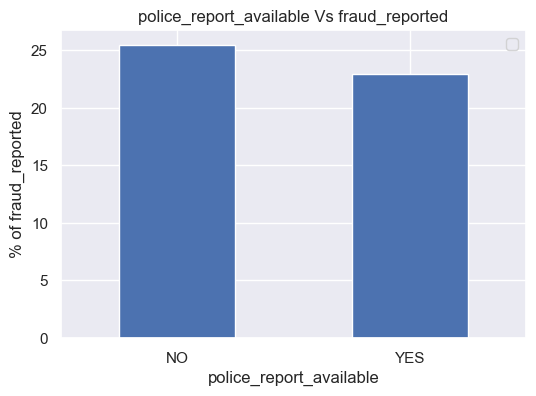

<Figure size 600x400 with 0 Axes>

fraud_reported,N,Y
police_report_available,,
NO,74.49,25.51
YES,77.07,22.93


In [60]:
bivariate_eda(insurance_data,'police_report_available','fraud_reported',0)

    The insurance claims for which the police_report_avaiable will be more authentic with accurate facts and figures of the incident, while the ones for which police_report column is a "NA" has more chances of committing fraud.

In [61]:
def cat_2_cat_relationship(data,col1,col2,rot):
    cross_tab = pd.crosstab(data[col1], data[col2]).apply(lambda x: x/x.sum() * 100, axis = 1).round(2)
    cross_tab.plot.bar()
    plt.xlabel('{}'.format(col1))
    plt.ylabel('% of {}'.format(col2))
    plt.title('{} Vs {}'.format(col1,col2))
    plt.xticks(rotation=rot)
    plt.figure(figsize=(12,8))
    plt.show()
    return cross_tab
        

#### <font color='maroon'> incident_type Vs incident_severity </font>

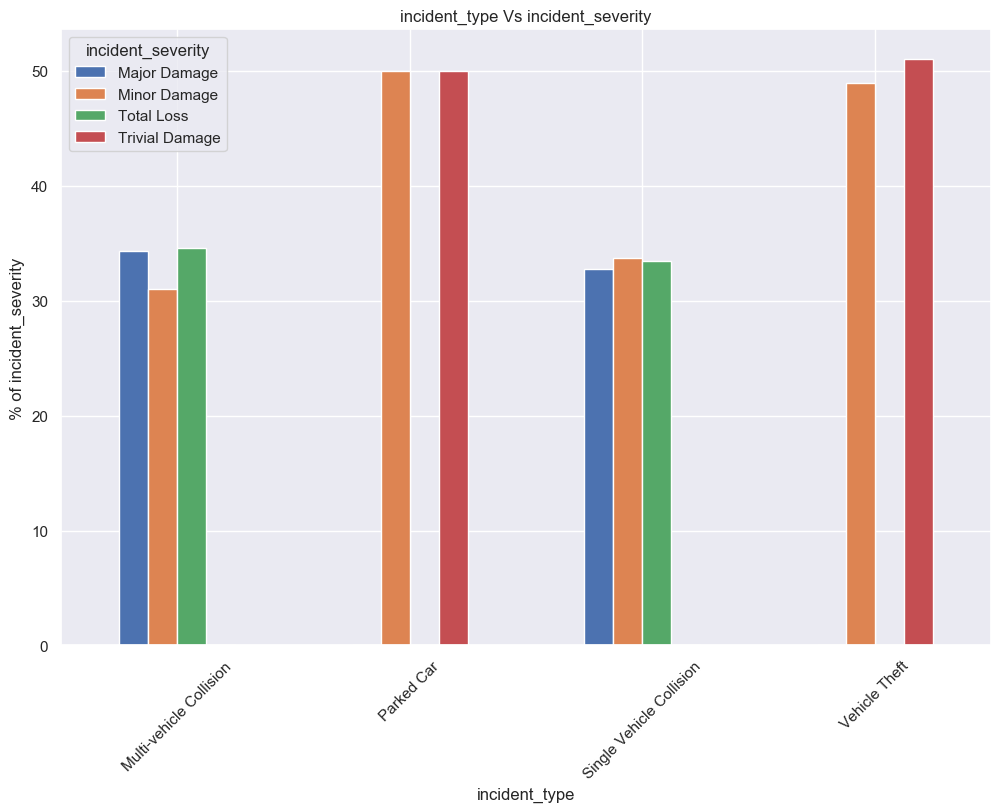

<Figure size 1200x800 with 0 Axes>

incident_severity,Major Damage,Minor Damage,Total Loss,Trivial Damage
incident_type,,,,
Multi-vehicle Collision,34.37,31.03,34.61,0.00
Parked Car,0.00,50.00,0.00,50.00
Single Vehicle Collision,32.75,33.75,33.50,0.00
Vehicle Theft,0.00,48.94,0.00,51.06


In [62]:
cat_2_cat_relationship(insurance_data,'incident_type','incident_severity',45)

    "Parked Car" and "Vehicle Theft" are causing Minor Damage and Trivial Damages. While "Multi-vehicle Collision" and "Single Vehicle Collision" are causing Major Damage, Minor Damages or Total Loss.

#### <font color = 'maroon'> Hypothesis test using Chi-Square</font>

    Let us consider the categorical variables, except target variable:-
    

In [63]:
cat_cols = []
for cols in insurance_data.select_dtypes(include='category'):
    if cols == 'fraud_reported':
        continue
    cat_cols.append(cols)
        

In [64]:
# For using the chi_square test
from scipy.stats import chi2_contingency
from scipy import stats
from scipy.stats import chi2

In [65]:
cat_features_paired = [(i,j) for i in cat_cols for j in cat_cols]
chi2, p_values = [], []

for col in cat_features_paired:
    if col[0] != col[1]:
        contigency_table = pd.DataFrame(pd.crosstab(insurance_data[col[0]],insurance_data[col[1]]))
        print('Contigency Table : ',contigency_table)

Contigency Table :  policy_csl    100/300  250/500  500/1000
policy_state                            
IL                118      113       107
IN                115      107        88
OH                116      131       105
Contigency Table :  policy_deductable  500   1000  2000
policy_state                       
IL                  114   117   107
IN                  110   116    84
OH                  118   118   116
Contigency Table :  insured_sex   FEMALE  MALE
policy_state              
IL               179   159
IN               163   147
OH               195   157
Contigency Table :  insured_education_level  Associate  College  High School  JD  MD  Masters  PhD
policy_state                                                                  
IL                              41       45           56  50  46       52   48
IN                              42       34           54  61  46       45   28
OH                              62       43           50  50  52       46   49
Conti

Contigency Table :  witnesses      0   1   2   3
policy_state                
IL            89  84  89  76
IN            80  76  73  81
OH            80  98  88  86
Contigency Table :  police_report_available   NO  YES
policy_state                     
IL                       245   93
IN                       213   97
OH                       228  124
Contigency Table :  auto_make     Accura  Audi  BMW  Chevrolet  Dodge  Ford  Honda  Jeep  \
policy_state                                                           
IL                16    27   39         22     26    22     14    28   
IN                25    19   12         30     27    22     19    22   
OH                27    23   21         24     27    28     22    17   

auto_make     Mercedes  Nissan  Saab  Suburu  Toyota  Volkswagen  
policy_state                                                      
IL                  20      24    29      28      21          22  
IN                  18      24    20      24      24          2

Contigency Table :  incident_location  1012 5th Lane  1028 Sky Lane  1030 Pine Lane  \
policy_csl                                                        
100/300                        0              1               1   
250/500                        0              0               0   
500/1000                       1              0               0   

incident_location  1087 Flute Drive  1091 1st Drive  1102 Apache Hwy  \
policy_csl                                                             
100/300                           0               1                0   
250/500                           1               0                0   
500/1000                          0               0                1   

incident_location  1110 4th Drive  1123 5th Lane  1126 Texas Hwy  \
policy_csl                                                         
100/300                         1              0               0   
250/500                         0              1               1   
500/1000   

Contigency Table :  collision_type     Front Collision  Rear Collision  Side Collision  Unknown
policy_deductable                                                          
500                             81             104              97       60
1000                            83             101             102       65
2000                            90              87              77       53
Contigency Table :  incident_severity  Major Damage  Minor Damage  Total Loss  Trivial Damage
policy_deductable                                                        
500                          98           118          94              32
1000                         90           127         100              34
2000                         88           109          86              24
Contigency Table :  authorities_contacted  Ambulance  Fire  None  Other  Police
policy_deductable                                          
500                           56    85    27     71     103
1000      

Contigency Table :  auto_model         3 Series  92x  93  95  A3  A5  Accord  C300  CRV  Camry  \
policy_deductable                                                            
500                       6   12   9  10  12   7       2     6    5     10   
1000                      7   11   8  13  10  11       5     6    9      7   
2000                      5    5   8   4  15  14       6     6    6     11   

auto_model         Civic  Corolla  E400  Escape  F150  Forrestor  Fusion  \
policy_deductable                                                          
500                   15        5    12       9    11         10       6   
1000                   2        9     8       9     7         11       6   
2000                   5        6     7       6     9          7       9   

auto_model         Grand Cherokee  Highlander  Impreza  Jetta  Legacy  M5  \
policy_deductable                                                           
500                             6           9        4

Contigency Table :  policy_csl               100/300  250/500  500/1000
insured_education_level                            
Associate                     42       50        53
College                       49       47        26
High School                   54       56        50
JD                            62       59        40
MD                            61       43        40
Masters                       44       45        54
PhD                           37       51        37
Contigency Table :  policy_deductable        500   1000  2000
insured_education_level                  
Associate                  50    48    47
College                    39    47    36
High School                55    63    42
JD                         62    54    45
MD                         46    43    55
Masters                    46    58    39
PhD                        44    38    43
Contigency Table :  insured_sex              FEMALE  MALE
insured_education_level              
Associate         

... (32 outputs left out)

Contigency Table :  auto_model  3 Series  92x  93  95  A3  A5  Accord  C300  CRV  Camry  Civic  \
auto_make                                                                    
Accura             0    0   0   0   0   0       0     0    0      0      0   
Audi               0    0   0   0  37  32       0     0    0      0      0   
BMW               18    0   0   0   0   0       0     0    0      0      0   
Chevrolet          0    0   0   0   0   0       0     0    0      0      0   
Dodge              0    0   0   0   0   0       0     0    0      0      0   
Ford               0    0   0   0   0   0       0     0    0      0      0   
Honda              0    0   0   0   0   0      13     0   20      0     22   
Jeep               0    0   0   0   0   0       0     0    0      0      0   
Mercedes           0    0   0   0   0   0       0    18    0      0      0   
Nissan             0    0   0   0   0   0       0     0    0      0      0   
Saab               0   28  25  27   0   0   

Contigency Table :  insured_hobbies  base-jumping  basketball  board-games  bungie-jumping  \
auto_model                                                               
3 Series                    0           1            0               0   
92x                         0           0            2               1   
93                          0           2            2               4   
95                          1           1            1               3   
A3                          3           1            2               4   
A5                          5           1            3               3   
Accord                      2           1            1               0   
C300                        0           2            0               0   
CRV                         2           0            2               0   
Camry                       6           1            1               1   
Civic                       3           0            0               2   
Corolla           

Contigency Table :  incident_state  NC  NY  OH  PA  SC  VA  WV
auto_model                                
3 Series         2   5   0   0   5   2   4
92x              4   5   0   1   9   3   6
93               3   6   0   0   4   4   8
95               2   5   0   0   6   4  10
A3               8   8   0   2   7   5   7
A5               5   5   0   1   9   4   8
Accord           1   5   1   0   2   1   3
C300             3   6   0   0   5   2   2
CRV              3   6   0   0   3   3   5
Camry            1   9   0   3   6   1   8
Civic            3   6   2   0   2   2   7
Corolla          3   7   0   0   1   3   6
E400             4   8   0   3   3   4   5
Escape           4   6   1   1   3   5   4
F150             3   6   2   1   8   3   4
Forrestor        1   6   1   0  12   3   5
Fusion           4   7   0   0   7   0   3
Grand Cherokee   2   4   0   1   5   6   7
Highlander       0   4   1   0   7   5   5
Impreza          1   8   0   0   5   1   5
Jetta            4   7   0   3   6

Contigency Table :  auto_make       Accura  Audi  BMW  Chevrolet  Dodge  Ford  Honda  Jeep  \
auto_model                                                               
3 Series             0     0   18          0      0     0      0     0   
92x                  0     0    0          0      0     0      0     0   
93                   0     0    0          0      0     0      0     0   
95                   0     0    0          0      0     0      0     0   
A3                   0    37    0          0      0     0      0     0   
A5                   0    32    0          0      0     0      0     0   
Accord               0     0    0          0      0     0     13     0   
C300                 0     0    0          0      0     0      0     0   
CRV                  0     0    0          0      0     0     20     0   
Camry                0     0    0          0      0     0      0     0   
Civic                0     0    0          0      0     0     22     0   
Corolla           

In [66]:
# Observed values
Observed_values = contigency_table.values
print("Observed_values : ",Observed_values)

Observed_values :  [[ 0  0 18  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 28  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 25  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 27  0  0  0]
 [ 0 37  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 32  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 13  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 18  0  0  0  0  0]
 [ 0  0  0  0  0  0 20  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 28  0]
 [ 0  0  0  0  0  0 22  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 20  0]
 [ 0  0  0  0  0  0  0  0 27  0  0  0  0  0]
 [ 0  0  0  0  0 24  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 27  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 28  0  0]
 [ 0  0  0  0  0 21  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 25  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 22  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 20  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0 35]
 [ 0  0  0  0  0  0  0  0  0  0  0 3

In [67]:
b = chi2_contingency(contigency_table)
Expected_values = b[3]
print("Expected values", Expected_values)

Expected values [[1.224 1.242 1.296 1.368 1.44  1.296 0.99  1.206 1.17  1.404 1.44  1.44
  1.26  1.224]
 [1.904 1.932 2.016 2.128 2.24  2.016 1.54  1.876 1.82  2.184 2.24  2.24
  1.96  1.904]
 [1.7   1.725 1.8   1.9   2.    1.8   1.375 1.675 1.625 1.95  2.    2.
  1.75  1.7  ]
 [1.836 1.863 1.944 2.052 2.16  1.944 1.485 1.809 1.755 2.106 2.16  2.16
  1.89  1.836]
 [2.516 2.553 2.664 2.812 2.96  2.664 2.035 2.479 2.405 2.886 2.96  2.96
  2.59  2.516]
 [2.176 2.208 2.304 2.432 2.56  2.304 1.76  2.144 2.08  2.496 2.56  2.56
  2.24  2.176]
 [0.884 0.897 0.936 0.988 1.04  0.936 0.715 0.871 0.845 1.014 1.04  1.04
  0.91  0.884]
 [1.224 1.242 1.296 1.368 1.44  1.296 0.99  1.206 1.17  1.404 1.44  1.44
  1.26  1.224]
 [1.36  1.38  1.44  1.52  1.6   1.44  1.1   1.34  1.3   1.56  1.6   1.6
  1.4   1.36 ]
 [1.904 1.932 2.016 2.128 2.24  2.016 1.54  1.876 1.82  2.184 2.24  2.24
  1.96  1.904]
 [1.496 1.518 1.584 1.672 1.76  1.584 1.21  1.474 1.43  1.716 1.76  1.76
  1.54  1.496]
 [1.36  1.38  1.44 

In [68]:
no_of_rows = contigency_table.shape[0]
no_of_cols = contigency_table.shape[1]

ddof = (no_of_rows - 1) * (no_of_cols - 1)
print("Degree of Freedom:",ddof)
alpha = 0.05


Degree of Freedom: 494


In [69]:
chi_square = sum([(o-e) **2./e for o,e in zip(Observed_values,Expected_values )])
chi_square_statistic = chi_square[0] + chi_square[1]
print("chi-square statistic :",chi_square_statistic)

chi-square statistic : 1863.0000000000002


In [70]:
critical_value = chi2.ppf(q=1-alpha,df=ddof)
print('critical_value:',critical_value)

critical_value: 546.813624834911


In [71]:
# p-value
p_value = 1-chi2.cdf(x=chi_square_statistic, df=ddof)
print('p-value:',p_value)

p-value: 0.0


In [72]:
print('Significance Level :',alpha)
print('Degree of Freedom :',ddof)
print('chi-square statistic :',chi_square_statistic)
print('critical_value:',critical_value)
print('p-value:',p_value)

Significance Level : 0.05
Degree of Freedom : 494
chi-square statistic : 1863.0000000000002
critical_value: 546.813624834911
p-value: 0.0


In [73]:
if chi_square_statistic >= critical_value:
    print("Reject H0, There is a relationship between categorical variables")
else:
    print("Retain H0, There is no relationship between categorical variables")

Reject H0, There is a relationship between categorical variables


In [74]:
if p_value <= alpha:
    print("Reject H0, There is a relationship between categorical variables")
else:
    print("Retain H0, There is no relationship between categorical variables")

Reject H0, There is a relationship between categorical variables


Thus, from hypothesis testing we find out that there is relationship between categorical variables.

#### <font color = 'maroon'> Multivariate analysis in Continuous Features </font>

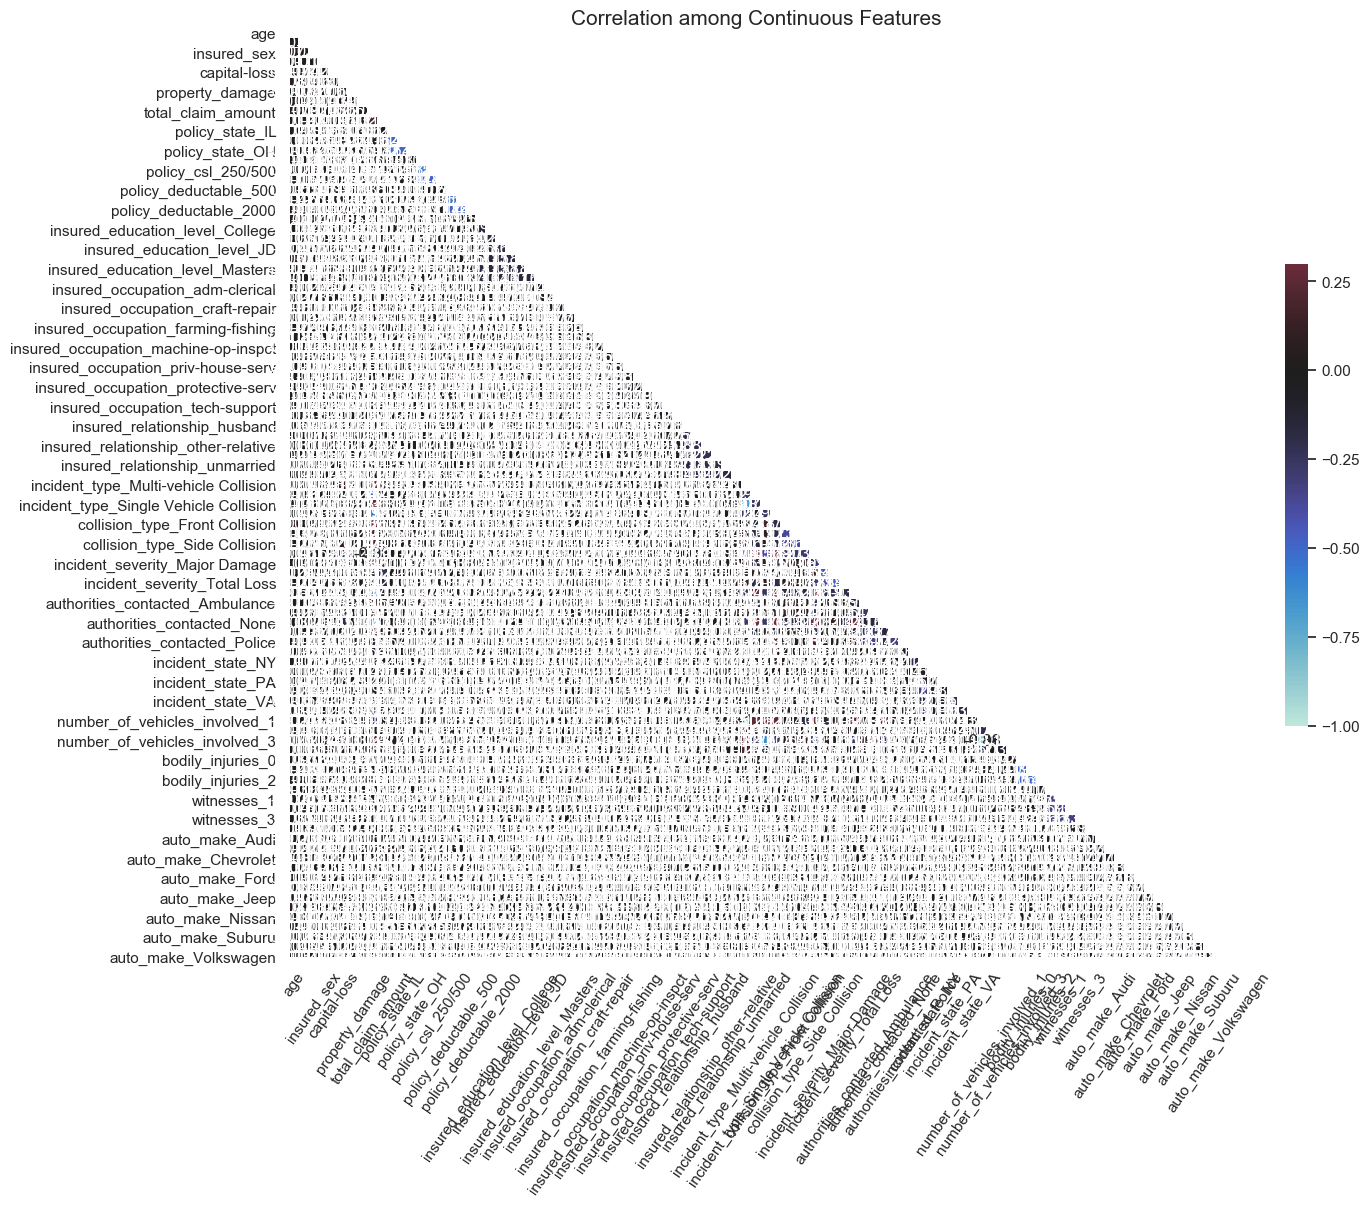

In [113]:
sns.set(style='white')

# Compute the correlation matrix
corr = insurance_data.corr()

# Generate a mask for the upper triangle
mask = np.zeros_like(corr, dtype=np.bool)
mask[np.triu_indices_from(mask)] = True

# Set up the matplotlib figure
f, ax= plt.subplots(figsize=(16,12))

# Generate a custom diverging colormap
#cmap = sns.diverging_palette(220,10,as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, vmax=.3, center=0,
            square=True, linewidth=.5, cbar_kws={"shrink": .5}, annot=True);
plt.xticks(rotation=55)
plt.title("Correlation among Continuous Features", fontsize=15)

plt.show()

    From the heatmap, we see that there is a relationship between "age" and "months_as_customer" , also a relationship between "total_claim_amount","injury_claim","property_claim" and "vehicle_claim". The rest other features don't have a significant relationship among them.

#### <font color='maroon'> age Vs fraud_reported </font>

In [ ]:
sns.swarmplot(x='age',y='fraud_reported', data=insurance_data);

    From above graph, we see that the policy_holders committing fraud are in the age group 31-41. This is also the Income group. Also, the group which applies for many insurance policies. Hence, chances are there for them to do a great amount of error.

#### <font color='maroon'>total_claim_amount Vs fraud_reported</font>

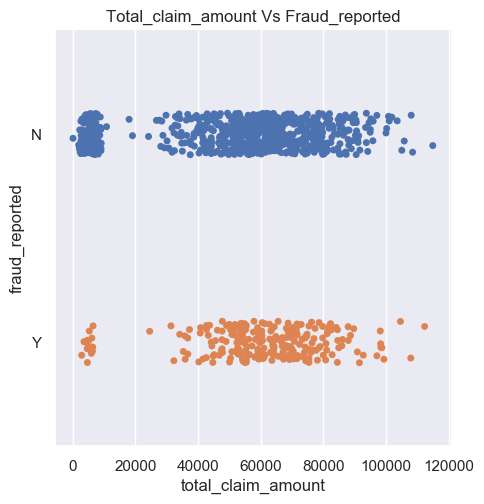

In [76]:
sns.set(rc={'figure.figsize':(12,4)})
sns.catplot(x='total_claim_amount',y='fraud_reported',data=insurance_data)

plt.title('Total_claim_amount Vs Fraud_reported')

plt.show()


    We aren't observing any pattern for fraud's on comparing with 'total_claim_amount'. Hence, this feature wouldn't provide more useful information in detecting fraud.

#### <font color='maroon'> auto_claim_amount for past 2 decades </font>

In [77]:
claim_data = [go.Bar(x=insurance_data['auto_year'], y=insurance_data['total_claim_amount'])]
  
layout = go.Layout(title='Auto Claims Past 2 decades', xaxis = dict(title='Year'), yaxis=dict(title='Total Claim Amount'))

fig = go.Figure(data=claim_data, layout = layout)

py.iplot(fig, filename='bar')
                                                                                              




#### <font color='maroon'>Plotting feature incident_state with various claims using Maps</font>

In [78]:
claims_col = ['incident_city','incident_location','vehicle_claim','property_claim','injury_claim',
              'total_claim_amount']

for col in insurance_data[claims_col]:
    insurance_data[claims_col] = insurance_data[claims_col].astype(str)
    

insurance_data['text'] = 'City:' + insurance_data['incident_city'] + '<br>' + \
    'location: ' + insurance_data['incident_location'] + '<br>' + \
    'vehicle_claim : '+ insurance_data['vehicle_claim'] + '<br>' + \
    'property_claim : ' + insurance_data['property_claim'] + '<br>' + \
    'injury_claim :' + insurance_data['injury_claim']



fig = go.Figure(data=go.Choropleth(
    locations=insurance_data['incident_state'], # Spatial coordinates
    z = insurance_data['total_claim_amount'], # Data to be color-coded
    locationmode = 'USA-states', # set of locations match entries in `locations`
    colorscale = 'Reds',
    autocolorscale = False,
    text = insurance_data['text'],
    marker_line_color = 'white',
    colorbar_title = "Millions USD",
))

fig.update_layout(
    title_text = 'Insurance Incident Claims State',
    geo = dict(
               scope = 'usa',
               projection = go.layout.geo.Projection(type='albers usa'),
               showlakes = True,
               lakecolor = 'rgb(255, 255, 255)'),
)

fig.show()

In [79]:
# Converting column 'total_claim_amount' to float after visualization
insurance_data['total_claim_amount'] = insurance_data['total_claim_amount'].astype(float)

In [80]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 40 columns):
months_as_customer             1000 non-null int64
age                            1000 non-null int64
policy_number                  1000 non-null int64
policy_bind_date               1000 non-null datetime64[ns]
policy_state                   1000 non-null category
policy_csl                     1000 non-null category
policy_deductable              1000 non-null category
policy_annual_premium          1000 non-null float64
umbrella_limit                 1000 non-null int64
insured_zip                    1000 non-null int64
insured_sex                    1000 non-null category
insured_education_level        1000 non-null category
insured_occupation             1000 non-null category
insured_hobbies                1000 non-null category
insured_relationship           1000 non-null category
capital-gains                  1000 non-null int64
capital-loss                   1000 non-nul

    The features which have strong relationship among them we will retain only one among them, since retaining other correlated features would add up to multicollinearity. Also, the features which don't add up further value while building model are being dropped.

In [81]:
insurance_data = insurance_data.drop(['auto_year','policy_bind_date','incident_date','injury_claim','property_claim','vehicle_claim',
             'insured_zip','policy_number','umbrella_limit','months_as_customer','policy_bind_date','incident_location','incident_city',
             'insured_hobbies','auto_model','text'],axis=1)

In [82]:
insurance_data.shape

(1000, 25)

### <font color='maroon'>Encoding Categorical Features </font>

In [83]:


# Target column
tgt_col = ['fraud_reported']
 
# Categorical cols
category_names = insurance_data.nunique()[insurance_data.nunique() < 15].keys().tolist()
category_names = [x for x in category_names if x not in tgt_col]

# Numerical cols
num_cols = [i for i in insurance_data.columns if i not in category_names+tgt_col]

# Binary cols
bin_cols = insurance_data.nunique()[insurance_data.nunique()==2].keys().tolist()

# Multi-cols
multi_cols = [i for i in category_names if i not in bin_cols]

# Label Encoding Binary cols
le = LabelEncoder()
for i in bin_cols:
    insurance_data[i] = le.fit_transform(insurance_data[i])
    
# Duplicating cols for multi-value columns
insurance_data = pd.get_dummies(data=insurance_data, columns=multi_cols)

In [84]:
insurance_data.head()

,age,policy_annual_premium,insured_sex,capital-gains,capital-loss,incident_hour_of_the_day,property_damage,police_report_available,total_claim_amount,fraud_reported,policy_state_IL,policy_state_IN,policy_state_OH,policy_csl_100/300,policy_csl_250/500,policy_csl_500/1000,policy_deductable_500,policy_deductable_1000,policy_deductable_2000,insured_education_level_Associate,...,bodily_injuries_1,bodily_injuries_2,witnesses_0,witnesses_1,witnesses_2,witnesses_3,auto_make_Accura,auto_make_Audi,auto_make_BMW,auto_make_Chevrolet,auto_make_Dodge,auto_make_Ford,auto_make_Honda,auto_make_Jeep,auto_make_Mercedes,auto_make_Nissan,auto_make_Saab,auto_make_Suburu,auto_make_Toyota,auto_make_Volkswagen
0,48,1406.91,1,53300,0,5,1,1,71610.0,1,0,0,1,0,1,0,0,1,0,0,...,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,42,1197.22,1,0,0,8,0,0,5070.0,1,0,1,0,0,1,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,29,1413.14,0,35100,0,7,0,0,34650.0,0,0,0,1,1,0,0,0,0,1,0,...,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,41,1415.74,0,48900,-62400,5,0,0,63400.0,1,1,0,0,0,1,0,0,0,1,0,...,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,44,1583.91,1,66000,-46000,20,0,0,6500.0,0,1,0,0,0,0,1,0,1,0,1,...,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


### <font color = 'maroon'> Normalizing Features </font>

In [85]:
cont_features=[]
for features in insurance_data.select_dtypes(include=['int64','float64']):
    cont_features.append(features)
    

In [86]:
insurance = insurance_data
# Scaling Numerical Cols
std_scaler = StandardScaler()
insurance[cont_features] = std_scaler.fit_transform(insurance[cont_features].values)

In [87]:
insurance.head()

,age,policy_annual_premium,insured_sex,capital-gains,capital-loss,incident_hour_of_the_day,property_damage,police_report_available,total_claim_amount,fraud_reported,policy_state_IL,policy_state_IN,policy_state_OH,policy_csl_100/300,policy_csl_250/500,policy_csl_500/1000,policy_deductable_500,policy_deductable_1000,policy_deductable_2000,insured_education_level_Associate,...,bodily_injuries_1,bodily_injuries_2,witnesses_0,witnesses_1,witnesses_2,witnesses_3,auto_make_Accura,auto_make_Audi,auto_make_BMW,auto_make_Chevrolet,auto_make_Dodge,auto_make_Ford,auto_make_Honda,auto_make_Jeep,auto_make_Mercedes,auto_make_Nissan,auto_make_Saab,auto_make_Suburu,auto_make_Toyota,auto_make_Volkswagen
0,0.990836,0.616705,1.076953,1.011331,0.953851,-0.956261,1.520282,1.478078,0.714257,1.746019,0,0,1,0,1,0,0,1,0,0,...,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,0.334073,-0.242521,1.076953,-0.901927,0.953851,-0.524475,-0.657773,-0.676554,-1.807312,1.746019,0,1,0,0,1,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,-1.088913,0.642233,-0.928546,0.358023,0.953851,-0.668404,-0.657773,-0.676554,-0.686362,-0.572731,0,0,1,1,0,0,0,0,1,0,...,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,0.224613,0.652886,-0.928546,0.853388,-1.267577,-0.956261,-0.657773,-0.676554,0.403135,1.746019,1,0,0,0,1,0,0,0,1,0,...,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,0.552994,1.341980,1.076953,1.467210,-0.683741,1.202666,-0.657773,-0.676554,-1.753121,-0.572731,1,0,0,0,0,1,0,1,0,1,...,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


In [123]:
insurance['fraud_reported'] = insurance_org['fraud_reported']
insurance['fraud_reported'].replace(to_replace=['N','Y'],value=[0,1],inplace=True)

In [124]:
# Fraud_reported count
count_fraud_N, count_fraud_Y = insurance_data.fraud_reported.value_counts()

# Divide by class 
insurance_class_Y = insurance_data[insurance_data['fraud_reported'] == '1']
insurance_class_N = insurance_data[insurance_data['fraud_reported'] == '0']

### <font color='Maroon'> Model Building</font>

In [125]:
# Converting features to X : Features, Y : Target
cols = [ i for i in insurance.columns if i != 'fraud_reported']
X = insurance[cols]
Y = pd.DataFrame(insurance['fraud_reported'])

In [126]:
X.head()

,age,policy_annual_premium,insured_sex,capital-gains,capital-loss,incident_hour_of_the_day,property_damage,police_report_available,total_claim_amount,policy_state_IL,policy_state_IN,policy_state_OH,policy_csl_100/300,policy_csl_250/500,policy_csl_500/1000,policy_deductable_500,policy_deductable_1000,policy_deductable_2000,insured_education_level_Associate,insured_education_level_College,...,bodily_injuries_1,bodily_injuries_2,witnesses_0,witnesses_1,witnesses_2,witnesses_3,auto_make_Accura,auto_make_Audi,auto_make_BMW,auto_make_Chevrolet,auto_make_Dodge,auto_make_Ford,auto_make_Honda,auto_make_Jeep,auto_make_Mercedes,auto_make_Nissan,auto_make_Saab,auto_make_Suburu,auto_make_Toyota,auto_make_Volkswagen
0,0.990836,0.616705,1.076953,1.011331,0.953851,-0.956261,1.520282,1.478078,0.714257,0,0,1,0,1,0,0,1,0,0,0,...,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,0.334073,-0.242521,1.076953,-0.901927,0.953851,-0.524475,-0.657773,-0.676554,-1.807312,0,1,0,0,1,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,-1.088913,0.642233,-0.928546,0.358023,0.953851,-0.668404,-0.657773,-0.676554,-0.686362,0,0,1,1,0,0,0,0,1,0,0,...,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,0.224613,0.652886,-0.928546,0.853388,-1.267577,-0.956261,-0.657773,-0.676554,0.403135,1,0,0,0,1,0,0,0,1,0,0,...,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,0.552994,1.341980,1.076953,1.467210,-0.683741,1.202666,-0.657773,-0.676554,-1.753121,1,0,0,0,0,1,0,1,0,1,0,...,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


In [133]:
Y['fraud_reported'] = Y['fraud_reported'].astype(str)
Y['fraud_reported'].value_counts()

0    753
1    247
Name: fraud_reported, dtype: int64

#### <font color='maroon'> Resampling Technique to overcome Imbalance in Dataset</font>

    While comparing the Fraud rate being reported in the donut shaped pie-chart, we could see imbalance in data. Hence, we will be using resampling technique to minimize this. We will be adopting the Oversampling techinque rather than Under-sampling technique, since the data size is small enough and furthermore reducing the size using undersampling would not provide expected predictions.

    We will create a 2-Dimensional plot function, to see the data distribution.

#### <font color='maroon'> Random over-sampling with imbalanced learn

In [226]:
ros = RandomOverSampler()
X_ros, Y_ros = ros.fit_sample(X,Y)

print(X_ros.shape[0]-X.shape[0],'new random picked points')



506 new random picked points


#### <font color='maroon'> Over-sampling : SMOTE </font>

    SMOTE(Synthetic Minority Oversampling Technique) consists of synthesizing elements for the minority class, based on those that already exist. It works by randomly picking a point from the minority class and computing the k-nearest neighbors for this point. The synthetic points are added between the chosen point and its neighbors.

In [227]:


smote = SMOTE(sampling_strategy='minority')
X_sm, Y_sm = smote.fit_sample(X,Y)




    We see that SMOTE technique would help us in better model prediction than RandomOverSampler technique, can you think why?
---

    It is based on KNN Technique.

    Using the variables obtained from SMOTE Technique in Model Building.

In [143]:
X_resampled_df = pd.DataFrame(X_sm, columns=X.columns)
Y_resampled_df = pd.DataFrame(Y_sm, columns= Y.columns )

In [144]:
Y_resampled_df.fraud_reported.value_counts()

0    753
1    753
Name: fraud_reported, dtype: int64

#### <font color='maroon'> Model selection using Stratified KFold </font>

    What is stratification? How does it help in this scenario?
---

    Stratification is the process of rearranging the data as to ensure each fold is good representative of the whole. In a binary classification problem where each class comprises 50% of the data, it is best to arrange the data such that each fold, each class comprises around half the instances. 

In [165]:
Y_train['fraud_reported'].value_counts()

0    602
1    198
Name: fraud_reported, dtype: int64

In [146]:
# Create Folds
folds = StratifiedKFold(n_splits=5,shuffle=True, random_state=0)

In [147]:
for train_index, test_index in folds.split(X,Y):
    
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    Y_train, Y_test = Y.iloc[train_index], Y.iloc[test_index]

    As the model target is to predict fraud is being reported or not while claiming insurance, so the problem tends to be of classification. Hence, we will be using the classficiation algorithms.

#### <font color='maroon'> Generic function for Logistic, KNN algorithm</font>

In [149]:
def generic_model(algorithm, train_x, test_x, train_y, test_y):
    
    algorithm.fit(train_x, train_y)
    prediction = algorithm.predict(test_x)
    probabilities = algorithm.predict_proba(test_x)
    
    print(algorithm)
    print(" ")
    print(" ")
    
    
    # Confusion Matrix
    labels=['Fraud','No-Fraud']
    conf_matrix = confusion_matrix(test_y, prediction)
    print("Confusion Matrix :",conf_matrix)
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(conf_matrix)
    plt.title("Confusion Matrix of the classifier")
    fig.colorbar(cax)
    ax.set_xticklabels([''] + labels)
    ax.set_yticklabels([''] + labels)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()
    
    
    # Classification report
    visualizer = ClassificationReport(algorithm, classes=['Fraud','No-Fraud'])
    visualizer.fit(train_x, train_y)
    visualizer.score(test_x, test_y)
    g = visualizer.poof()
    
    
    
    print("Accuracy Score : ", accuracy_score(test_y, prediction))
    
    # roc _auc_score
    model_roc_auc = roc_auc_score(test_y, prediction)
    print("Area under curve:", model_roc_auc)
    

#### <font color='maroon'> Logistic Regression </font>

In [150]:
logit = LogisticRegression(random_state=0)

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=100,
                   multi_class='ovr', n_jobs=1, penalty='l2', random_state=0,
                   solver='liblinear', tol=0.0001, verbose=0, warm_start=False)
 
 
Confusion Matrix : [[133  18]
 [ 28  21]]


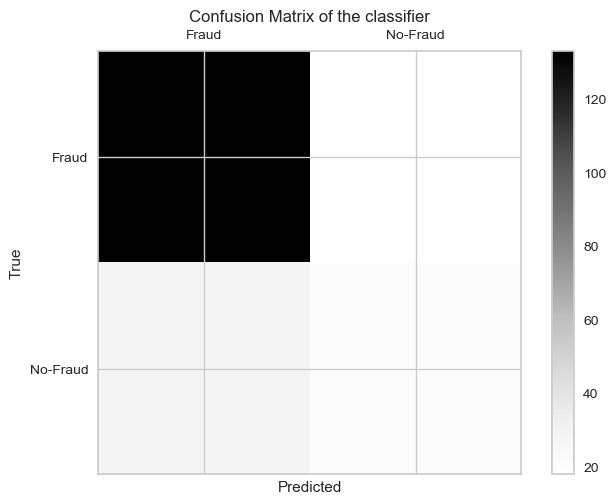

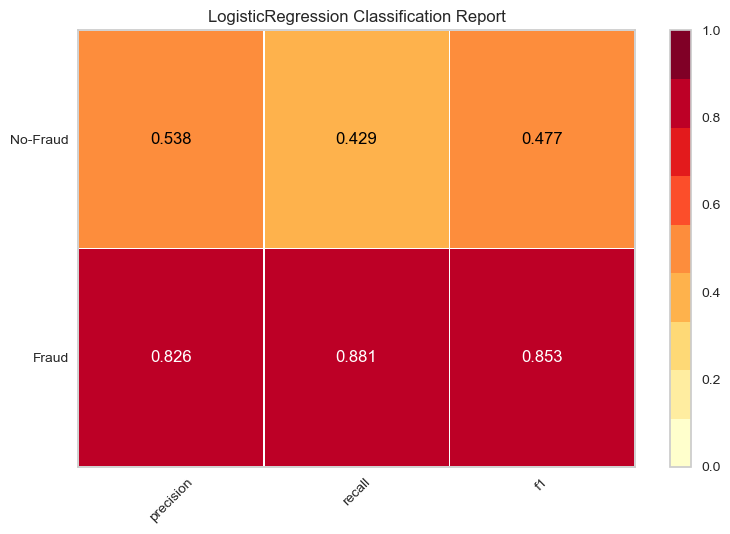

Accuracy Score :  0.77
Area under curve: 0.6546830652790919


In [151]:
rfe = RFE(logit,10)
rfe = rfe.fit(X_train, Y_train)

# Identified columns for Recursive Feature Elimination
rfe_df = pd.DataFrame({"rfe_support" : rfe.support_,
                        "columns":[ i for i in X_train.columns],
                        "ranking": rfe.ranking_,
                        })
    
logit_rfe  = LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
          intercept_scaling=1, max_iter=100, multi_class='ovr', n_jobs=1,
          penalty='l2', random_state=0, solver='liblinear', tol=0.0001,
          verbose=0, warm_start=False)

generic_model(logit_rfe,X_train,X_test,Y_train, Y_test)

tab_pl = ff.create_table(rfe_df)
py.iplot(tab_pl)

    We achieve an accuracy of 77% , with better precision , recall and f1-score.

#### <font color='maroon'> Generic Algorithm for Decision tree, Random Forest and Adaboost Classifier</font>

In [152]:
def baseline_model(algorithm, train_x, test_x, train_y, test_y, df):
    algorithm.fit(train_x, train_y)
    prediction = algorithm.predict(test_x)
    probabilities = algorithm.predict_proba(test_x)
    
    print(algorithm)
    print(" ")
    print(" ")
    
    
    # Confusion Matrix
    labels=['Fraud','No-Fraud']
    conf_matrix = confusion_matrix(test_y, prediction)
    print("Confusion Matrix :",conf_matrix)
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(conf_matrix)
    plt.title("Confusion Matrix of the classifier")
    fig.colorbar(cax)
    ax.set_xticklabels([''] + labels)
    ax.set_yticklabels([''] + labels)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()
    
    
    # Classification report
    visualizer = ClassificationReport(algorithm, classes=['Fraud','No-Fraud'])
    visualizer.fit(train_x, train_y)
    visualizer.score(test_x, test_y)
    g = visualizer.poof()
    
    # Create feature importances
    importances = algorithm.feature_importances_
    sorted_importances = np.sort(importances)
    reversed_importances = sorted_importances[::-1]
    
    
 
    
    indices = np.argsort(reversed_importances)[::-1]
    indices = indices[:10]
    
    plt.title("Feature Importances")
    plt.bar(range(len(indices)), reversed_importances[indices], color='b', align ='center')
    plt.xticks(range(len(indices)), [train_x.columns[i] for i in indices], rotation=55)
    plt.xlabel('Relative Importance')
    plt.show()
   
    
    print("Accuracy Score : ", accuracy_score(test_y, prediction))
    
    # roc _auc_score
    model_roc_auc = roc_auc_score(test_y, prediction)
    print("Area under curve:", model_roc_auc)
    

#### <font color='maroon'>Decision Tree Classifier</font>

In [153]:
dtc = DecisionTreeClassifier(random_state=0)

DecisionTreeClassifier(class_weight=None, criterion='gini', max_depth=None,
                       max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, presort=False,
                       random_state=0, splitter='best')
 
 
Confusion Matrix : [[177  48]
 [ 48 179]]


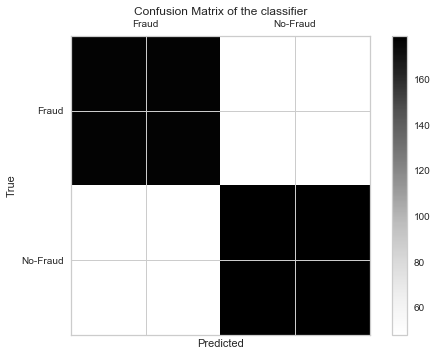

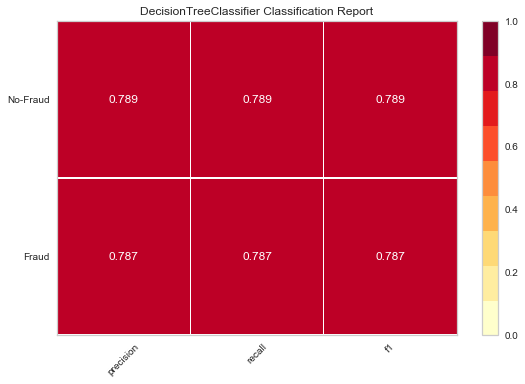

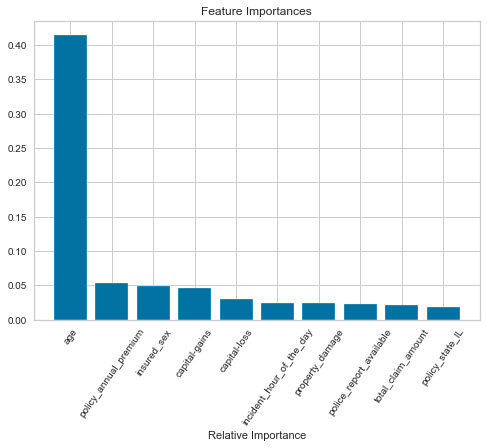

Accuracy Score :  0.7876106194690266
Area under curve: 0.7876064610866373


In [219]:
baseline_model(dtc,X_train,X_test,Y_train, Y_test, insurance)

    The precision , recall and f1-score are fairing better than accuracy score.That means the model is misclassifying the fraud as non-fraud.

#### <font color='maroon'> Random Forest Classifier</font>

In [154]:
rfc = RandomForestClassifier(random_state=0)

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='auto',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, n_estimators=100,
                       n_jobs=None, oob_score=False, random_state=0, verbose=0,
                       warm_start=False)
 
 
Confusion Matrix : [[139  12]
 [ 38  11]]


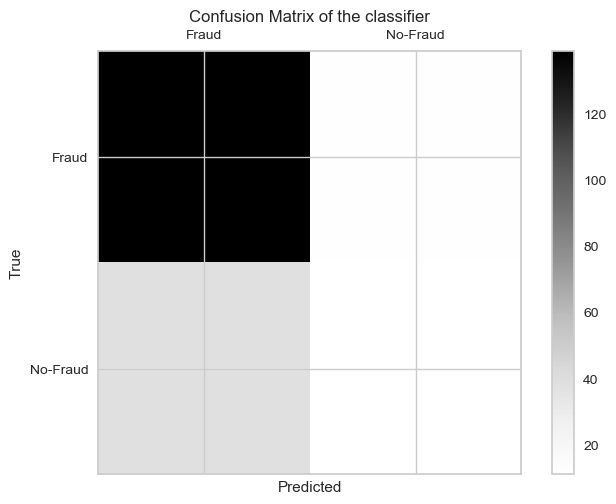

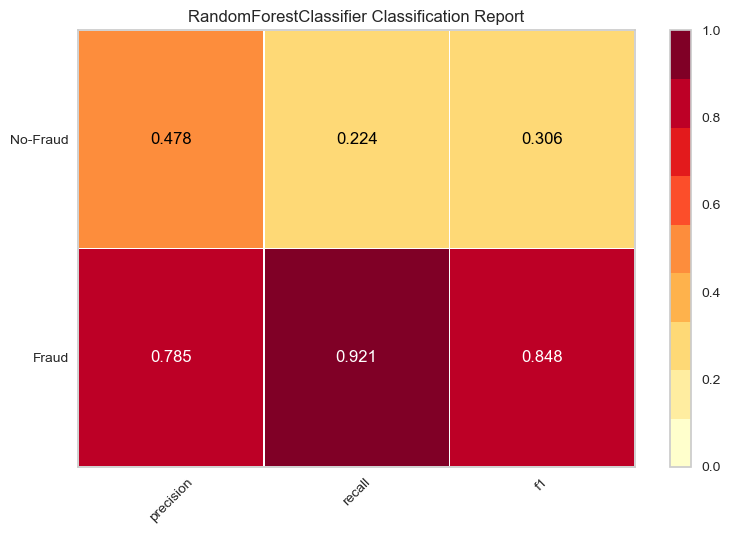

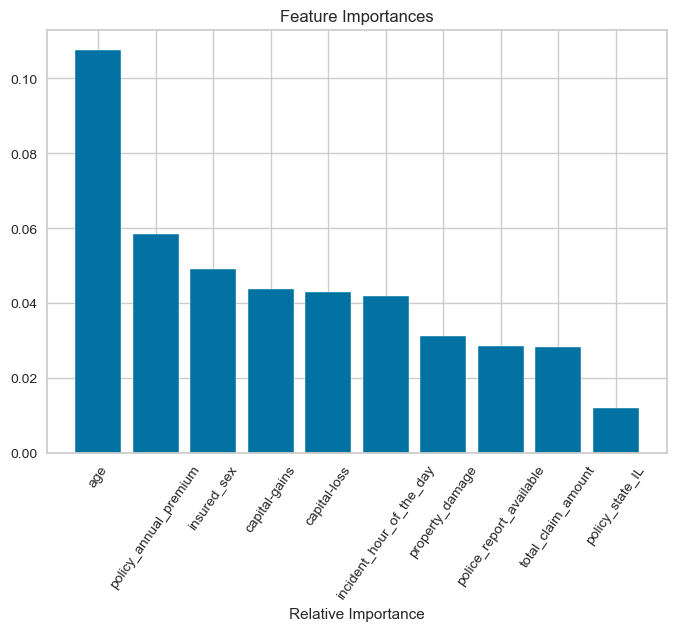

Accuracy Score :  0.75
Area under curve: 0.5725097986214354


In [155]:
baseline_model(rfc,X_train,X_test,Y_train, Y_test, insurance)

    We would expect RandomForest to give better scores than any algorithm used till now, but we only got 75%

#### <font color='maroon'> AdaBoost Classifier</font>

In [156]:
abc = AdaBoostClassifier(random_state=0)

AdaBoostClassifier(algorithm='SAMME.R', base_estimator=None, learning_rate=1.0,
                   n_estimators=50, random_state=0)
 
 
Confusion Matrix : [[128  23]
 [ 25  24]]


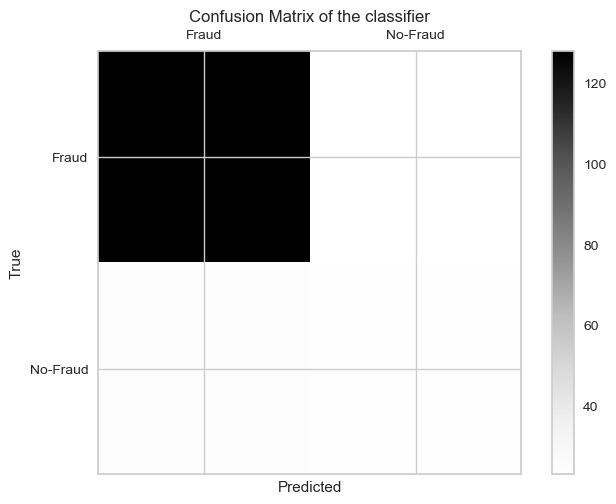

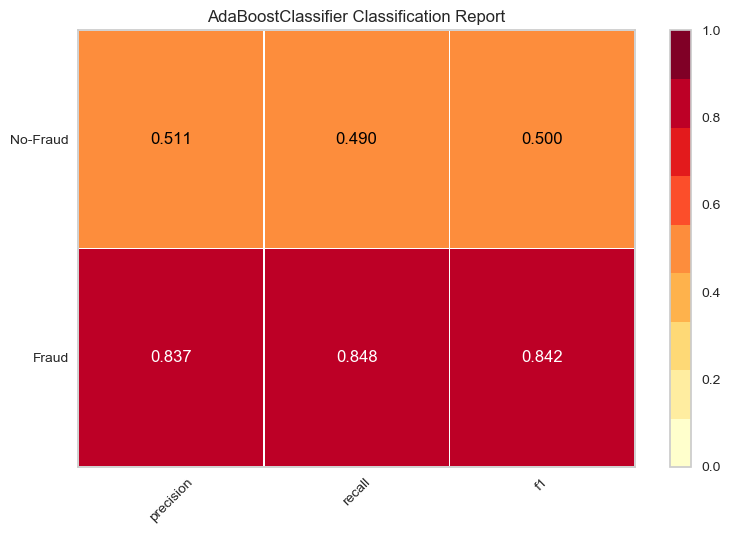

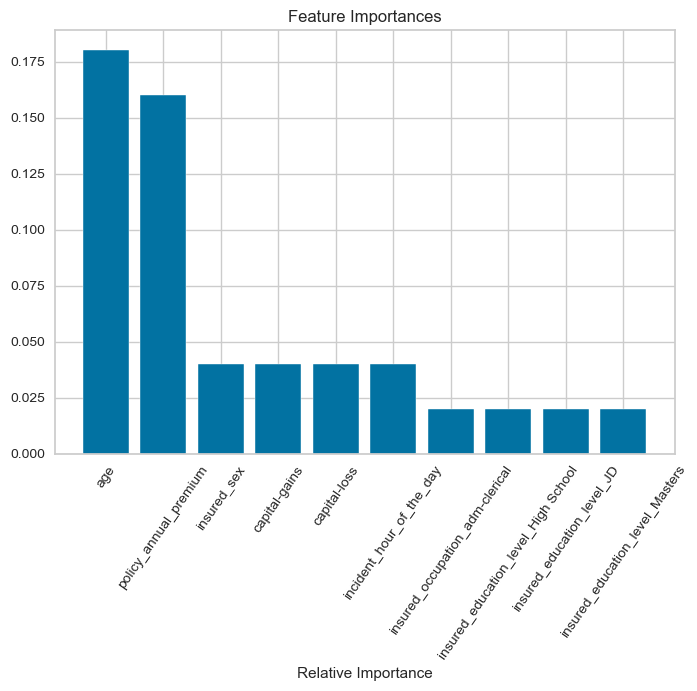

Accuracy Score :  0.76
Area under curve: 0.6687390187863225


In [157]:
baseline_model(abc,X_train,X_test,Y_train, Y_test, insurance)

    Adaboost is better in predicting fraud's than Random Forest. Why are we not getting good scores? how do we improve the current scores?
---
    
    We have only created baseline models, so we can improve scores by using Hyperparameter tuning

#### <font color='maroon'> Hyper-parameter tuning using GridSearchCV for Logistic Regression</font>

In [181]:
grid_values = {'penalty':['l1','l2'],'C':[0.001, .009, 0.01, .09, 1,5,10,25]}
grid_lr = GridSearchCV(logit, param_grid=grid_values, scoring='accuracy')

GridSearchCV(cv=None, error_score=nan,
             estimator=LogisticRegression(C=1.0, class_weight=None, dual=False,
                                          fit_intercept=True,
                                          intercept_scaling=1, l1_ratio=None,
                                          max_iter=100, multi_class='auto',
                                          n_jobs=None, penalty='l2',
                                          random_state=0, solver='lbfgs',
                                          tol=0.0001, verbose=0,
                                          warm_start=False),
             iid='deprecated', n_jobs=None,
             param_grid={'C': [0.001, 0.009, 0.01, 0.09, 1, 5, 10, 25],
                         'penalty': ['l1', 'l2']},
             pre_dispatch='2*n_jobs', refit=True, return_train_score=False,
             scoring='accuracy', verbose=0)
 
 
Confusion Matrix : [[134  17]
 [ 30  19]]


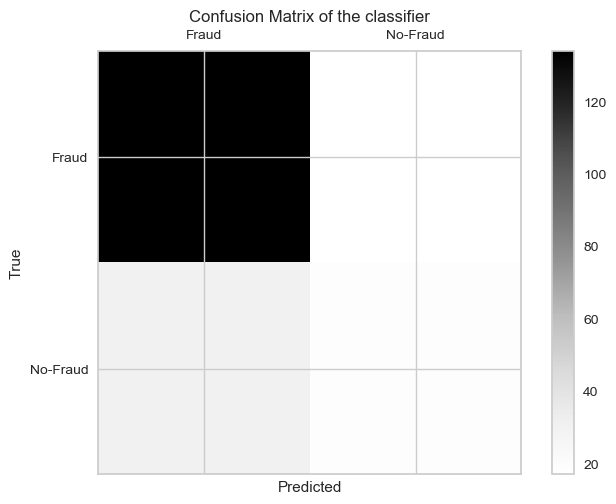

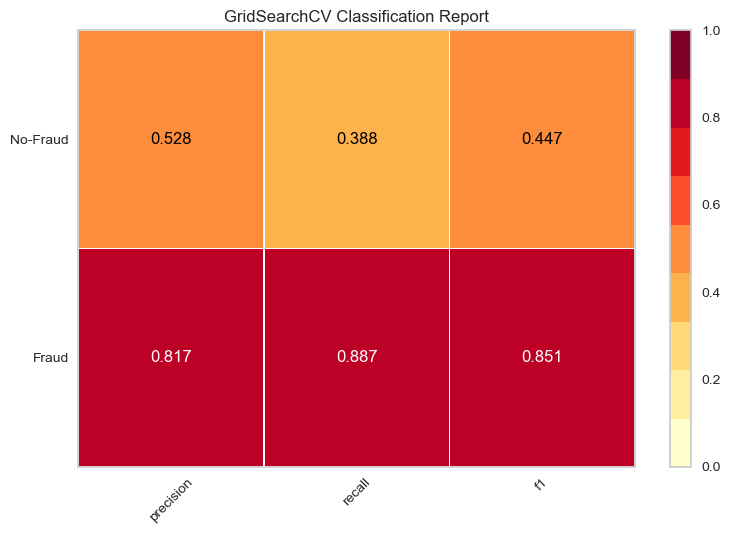

Accuracy Score :  0.765
Area under curve: 0.6375861602919313


In [182]:
generic_model(grid_lr,X_train,X_test,Y_train, Y_test)

    On hyper-tuning the accuracy has further dropped to 73%, with precision and f1-score reducing drastically.

#### <font color='maroon'> Hyper-parameter tuning for Decision Tree Classifier</font>

In [167]:
# Define the parameter values that should be searched
sample_split_range=range(10,50,100)
param_grid = dict(min_samples_split=sample_split_range)

# instiantiate the grid
grid_dtc = GridSearchCV(dtc, param_grid, cv=10, scoring='accuracy')


GridSearchCV(cv=10, error_score=nan,
             estimator=DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None,
                                              criterion='gini', max_depth=None,
                                              max_features=None,
                                              max_leaf_nodes=None,
                                              min_impurity_decrease=0.0,
                                              min_impurity_split=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              min_weight_fraction_leaf=0.0,
                                              presort='deprecated',
                                              random_state=0, splitter='best'),
             iid='deprecated', n_jobs=None,
             param_grid={'min_samples_split': range(10, 50, 100)},
             pre_dispatch='2*n_jobs', refit=True, return_tr

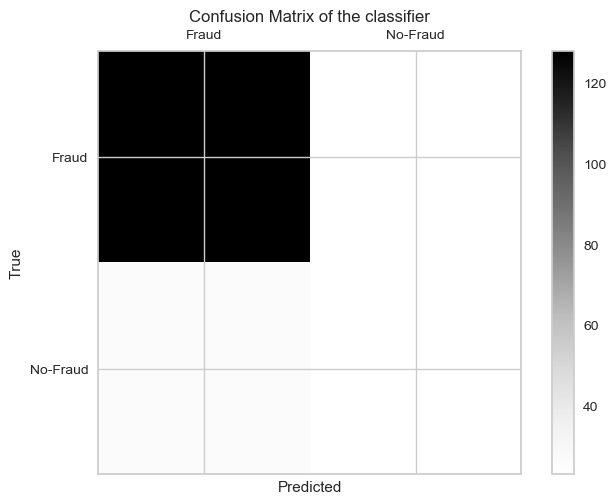

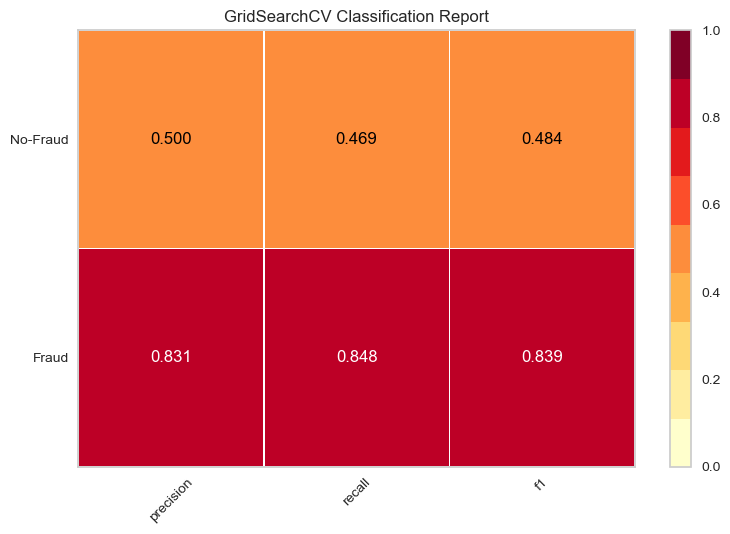

Accuracy Score :  0.755
Area under curve: 0.6585349371536694


In [168]:
generic_model(grid_dtc,X_train,X_test,Y_train, Y_test)

    The accuracy dropped from 77 to 75.5%

#### <font color='maroon'> Hyper-parameter tuning for RandomForest Classifier</font>

In [169]:
# Specifying the parameters
param_grid = {
               'max_depth':[80,90,100,110],
               'max_features':[2,3],
               'min_samples_leaf':[3,4,5],
               'min_samples_split':[8,10,12],
               'n_estimators':[100,200,300,1000]
}

# Instantiating the GridSearch Model
grid_rf = GridSearchCV(estimator=rfc, param_grid = param_grid, cv=3 , n_jobs=-1, verbose=2)

Fitting 3 folds for each of 288 candidates, totalling 864 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  33 tasks      | elapsed:   17.9s
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 357 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done 640 tasks      | elapsed:  5.4min
[Parallel(n_jobs=-1)]: Done 864 out of 864 | elapsed:  7.4min finished


GridSearchCV(cv=3, error_score=nan,
             estimator=RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                                              class_weight=None,
                                              criterion='gini', max_depth=None,
                                              max_features='auto',
                                              max_leaf_nodes=None,
                                              max_samples=None,
                                              min_impurity_decrease=0.0,
                                              min_impurity_split=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              min_weight_fraction_leaf=0.0,
                                              n_estimators=100, n_jobs=None,
                                              oob_score=False, random_state=0,
                                   

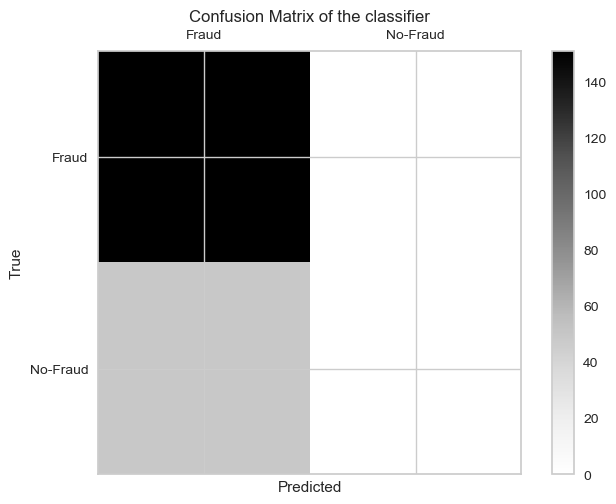

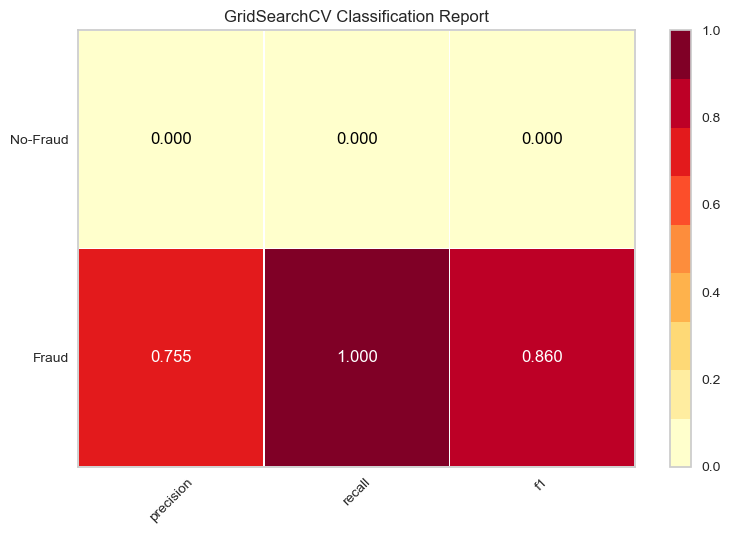

Accuracy Score :  0.755
Area under curve: 0.5


In [170]:
generic_model(grid_rf,X_train,X_test,Y_train, Y_test)

    No improvement in the performance, infact it's worse can you tell why?

#### <font color='maroon'> Hyperparameter tuning for AdaBoost Classifier</font>

In [171]:
grid_params = {
                'n_estimators':[100,200,300],
                
}

grid_abc = GridSearchCV(estimator=abc, param_grid=grid_params, scoring='accuracy',cv=3,n_jobs=-1)

GridSearchCV(cv=3, error_score=nan,
             estimator=AdaBoostClassifier(algorithm='SAMME.R',
                                          base_estimator=None,
                                          learning_rate=1.0, n_estimators=50,
                                          random_state=0),
             iid='deprecated', n_jobs=-1,
             param_grid={'n_estimators': [100, 200, 300]},
             pre_dispatch='2*n_jobs', refit=True, return_train_score=False,
             scoring='accuracy', verbose=0)
 
 
Confusion Matrix : [[130  21]
 [ 27  22]]


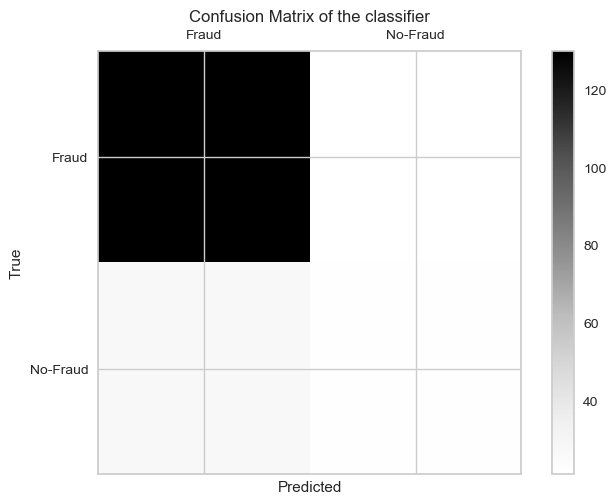

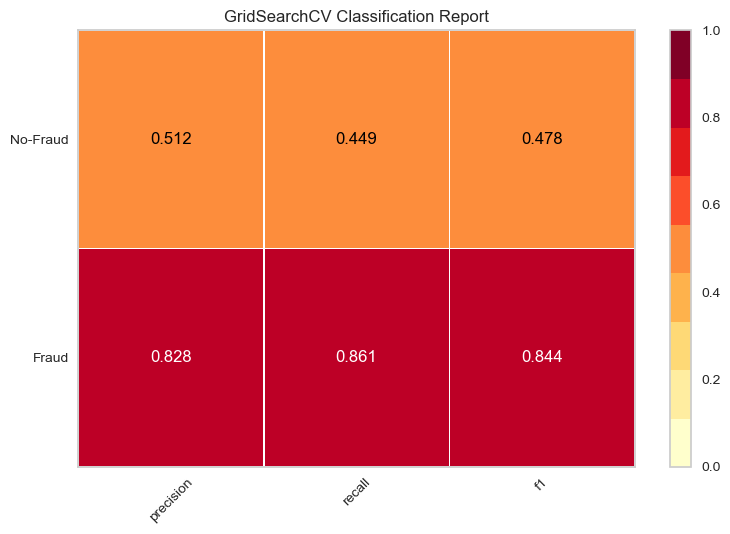

Accuracy Score :  0.76
Area under curve: 0.6549533720773077


In [172]:
generic_model(grid_abc,X_train,X_test,Y_train, Y_test)

    No improvement again, or isn't there?
---
    
    We have been looking at accuracy directly, but turn your eye to the classification report. We see that our model does a great job with Fradulent entries but not non-fraud. So very often it is preferred to refer to multiple metrics before coming to a conclusion about performance of a model.

#### <font color='maroon'> KNN </font>

In [173]:
knn = KNeighborsClassifier()

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                     metric_params=None, n_jobs=None, n_neighbors=5, p=2,
                     weights='uniform')
 
 
Confusion Matrix : [[139  12]
 [ 40   9]]


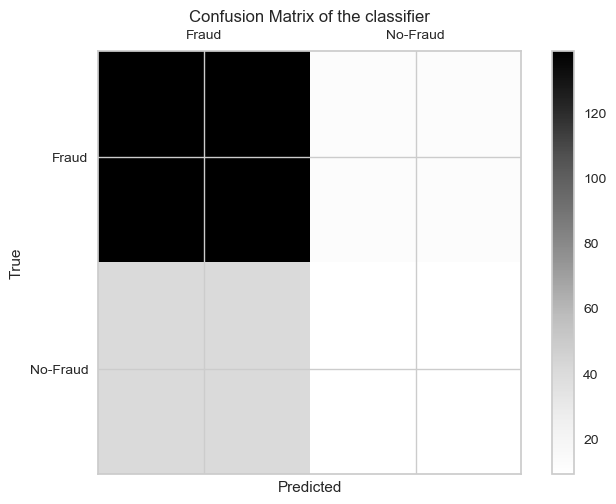

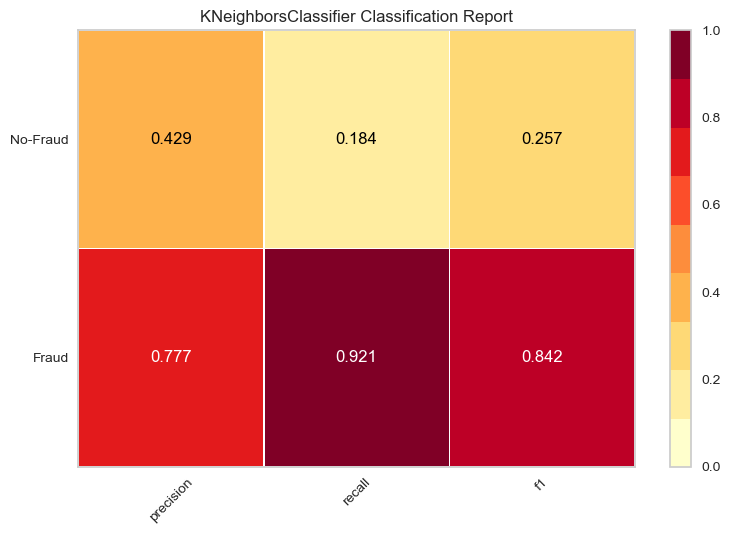

Accuracy Score :  0.74
Area under curve: 0.5521016353561292


In [174]:
generic_model(knn,X_train,X_test,Y_train, Y_test)

The results obtained for 'precision' are pretty great in predicting Fraud ,
which means most of Fraud are being predicted as "Fraud",but accuracy is a matter of concern from  this model.

#### <font color='maroon'> Hyperparameter tuning for KNN</font>

In [175]:
params = {
            'n_neighbors':[6,7,8,9,10],
            'leaf_size':[1,2,3,5],
            'weights':['uniform','distance'],
            'algorithm':['auto','ball_tree','kd_tree','brute'],
            'n_jobs':[-1]
}

In [176]:
# Making parameters with hyper parameter sets
grid_knn = GridSearchCV(knn,param_grid=params, n_jobs=-1)

GridSearchCV(cv=None, error_score=nan,
             estimator=KNeighborsClassifier(algorithm='auto', leaf_size=30,
                                            metric='minkowski',
                                            metric_params=None, n_jobs=None,
                                            n_neighbors=5, p=2,
                                            weights='uniform'),
             iid='deprecated', n_jobs=-1,
             param_grid={'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
                         'leaf_size': [1, 2, 3, 5], 'n_jobs': [-1],
                         'n_neighbors': [6, 7, 8, 9, 10],
                         'weights': ['uniform', 'distance']},
             pre_dispatch='2*n_jobs', refit=True, return_train_score=False,
             scoring=None, verbose=0)
 
 
Confusion Matrix : [[143   8]
 [ 38  11]]


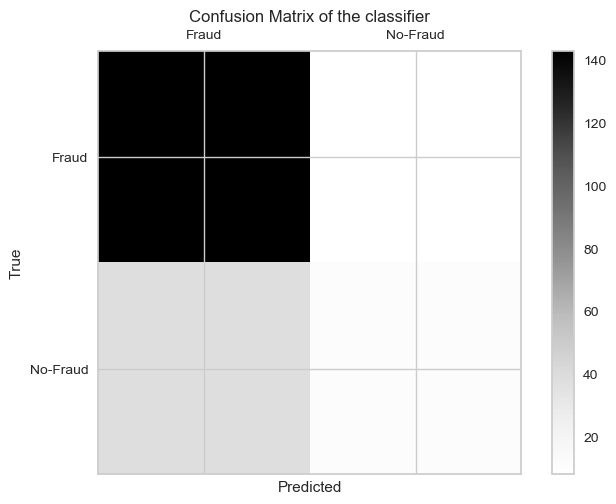

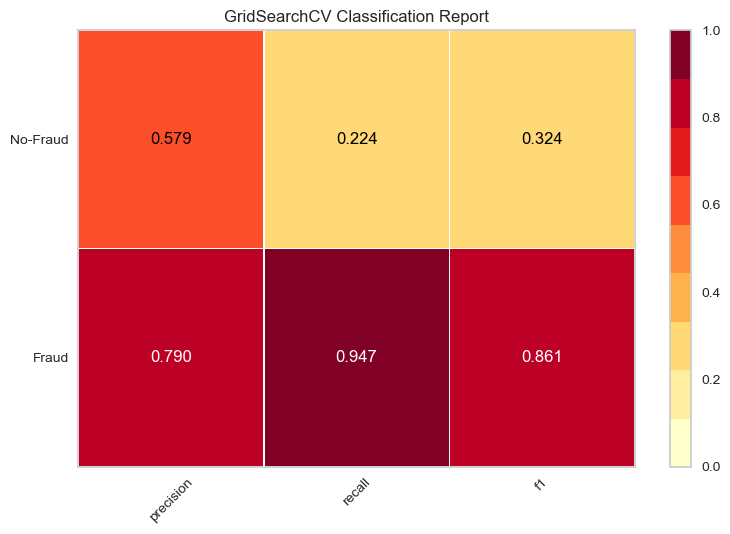

Accuracy Score :  0.77
Area under curve: 0.5857548317340181


In [177]:
generic_model(grid_knn,X_train,X_test,Y_train, Y_test)

    On hypertuning, however the accuracy of the model increased to a small amount and this is the only model with the improvement after hyperparameter tuning. Once again look at the recall for both classes

### <font color='maroon'> Model Performance Metrics </font>

In [186]:
def model_performance(model,train_x, test_x, train_y, test_y, name):
    model.fit(train_x, train_y)
    predictions = model.predict(test_x)
    accuracy = accuracy_score(test_y, predictions)
    recallscore = recall_score(test_y, predictions,pos_label='1')
    precision = precision_score(test_y, predictions,pos_label='1')
    roc_auc = roc_auc_score(test_y, predictions)
    f1score = f1_score(test_y, predictions,pos_label='1')
    
    df = pd.DataFrame({"Model": [name],
                       "Accuracy_score": [accuracy],
                       "Recall_score" : [recallscore],
                       "Precision": [precision],
                       "f1_score": [f1score],
                       "Area_under_curve": [roc_auc]
                      })
    return df


# Outputs for all model
model1 = model_performance(logit_rfe,X_train,X_test,Y_train, Y_test,"Logistic" )
model2 = model_performance(dtc, X_train, X_test, Y_train, Y_test,"Decision Tree")
model3 = model_performance(rfc, X_train, X_test, Y_train, Y_test,"Random Forest")
model4 = model_performance(abc, X_train, X_test, Y_train, Y_test,"AdaBoost")
model5 = model_performance(knn, X_train, X_test, Y_train, Y_test,"Knn")


# Concat all models
model_performances = pd.concat([model1, model2, model3, model4, model5], axis=0).reset_index()

model_performances = model_performances.drop(columns="index",axis=1)

table = ff.create_table(np.round(model_performances,4))

py.iplot(table)

#### <font color='maroon'> Accuracy of models on Hyperparameter Tuning </font>

In [187]:
# Outputs for all model
model1 = model_performance(grid_lr,X_train,X_test,Y_train, Y_test,"Logistic" )
model2 = model_performance(grid_dtc, X_train, X_test, Y_train, Y_test,"Decision Tree")
model3 = model_performance(grid_rf, X_train, X_test, Y_train, Y_test,"Random Forest")
model4 = model_performance(grid_abc, X_train, X_test, Y_train, Y_test,"AdaBoost")
model5 = model_performance(grid_knn, X_train, X_test, Y_train, Y_test,"Knn")


# Concat all models
model_performances = pd.concat([model1, model2, model3, model4, model5], axis=0).reset_index()

model_performances = model_performances.drop(columns="index",axis=1)

table = ff.create_table(np.round(model_performances,4))

py.iplot(table)

Fitting 3 folds for each of 288 candidates, totalling 864 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  33 tasks      | elapsed:   21.2s
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 357 tasks      | elapsed:  3.1min
[Parallel(n_jobs=-1)]: Done 640 tasks      | elapsed:  5.6min
[Parallel(n_jobs=-1)]: Done 864 out of 864 | elapsed:  7.8min finished


    Based on the above table, what can you say?
---
    
    AdaBoost is a clear winner. It has dominance in pretty much all metrics. It is also arguable that DecisionTree is the best too, but we can pick either of these and concentrate on improving them

### The conclusion
    Like any other datatale, this isn't the end for this one too. When you perform all the above steps, you might get better performing model with some other algorithm or sometimes worse performance too. But that doesn't mean there's no scope for improvement, it is always there and will be achieved when we keep training. Apparently, It's not just man that gets better with practice but also the machines 